# Лекция 13. Быстрая генерация: samplers, flow matching, distillation

Курс «Современное компьютерное зрение». Блокнот рассчитан на Google Colab: все ячейки выполняются сверху вниз без дополнительной настройки. Нужны только torch, torchvision, scipy и matplotlib, которые в Colab уже установлены; MNIST скачивается автоматически.

Сохранённые выводы получены на CPU в режиме `FAST_DEV_RUN`: сети облегчены, обучение сокращено. Ветка для GPU в Colab написана, но не проверялась. На GPU числа будут другими, поэтому переносить стоит направления эффектов, а не сами значения.

Лекция продолжает лекцию 12. Там диффузионная модель генерировала изображение за десятки и сотни вызовов сети. Здесь разбираются три способа сократить число вызовов: лучше решать уравнение, сделать траектории прямее, обучить быстрого ученика.

## Цели лекции

После лекции слушатель должен уметь:

1. записать probability flow ODE для гауссова пути зашумления и показать, что DDIM — это метод Эйлера (а точнее, экспоненциальный интегратор первого порядка) для неё;
2. объяснить, откуда берётся порядок точности решателя, и вывести шаг DPM-Solver++(2M) в переменной $\lambda = \log(\alpha/\sigma)$;
3. сравнить детерминированные (ODE) и стохастические (SDE, predictor-corrector) сэмплеры при равном бюджете вызовов сети;
4. вывести функцию потерь conditional flow matching и доказать, что её градиент совпадает с градиентом недоступной «маргинальной» потери;
5. объяснить, почему маргинальные траектории rectified flow искривлены, как reflow их выпрямляет и почему транспортная стоимость при этом не растёт;
6. описать progressive distillation и consistency distillation и понимать, какую цель видит ученик в каждом из них;
7. честно сравнивать методы: при равном NFE, по времени генерации с учётом стоимости обучения, через Парето-фронт «качество — время».

## Обозначения

| Символ | Смысл |
|---|---|
| $x_0 \sim p_{\text{data}}$ | изображение (данные); в этой лекции $t = 0$ — данные |
| $x_1 = \epsilon \sim \mathcal N(0, I)$ | шум; $t = 1$ — чистый шум |
| $x_t = \alpha_t x_0 + \sigma_t \epsilon$ | гауссов путь зашумления; основной случай: $\alpha_t = 1 - t,\ \sigma_t = t$ |
| $\lambda_t = \log(\alpha_t/\sigma_t)$ | половина логарифма отношения сигнал/шум (log-SNR) |
| $u_t(x)$, $v_\theta(x, t)$ | истинное и выученное векторное поле (скорость) |
| $\hat x_0,\ \hat\epsilon$ | предсказания данных и шума, восстановленные из $v_\theta$ |
| NFE | number of function evaluations — число вызовов сети на один образец |
| $f_\theta(x_t, t)$ | consistency-функция: сразу отображает $x_t$ в $x_0$ |
| $S$ | мера искривлённости траекторий (straightness), раздел 5.2 |
| FD, acc | расстояние Фреше в признаках классификатора и точность класса, как в лекции 12 |

Направление времени здесь такое же, как в rectified flow и Stable Diffusion 3: генерация идёт от $t = 1$ к $t = 0$. В лекции 12 время DDPM было дискретным, $t = 0, \dots, T$, а сеть предсказывала $\epsilon$. Сеть этой лекции предсказывает скорость $v$. Все три параметризации переводятся друг в друга (раздел 4.4).

## Структура

Часть I «Теория»:

1. NFE и три пути ускорения.
2. ODE-формулировка и DDIM.
3. Решатели высокого порядка: Heun, DPM-Solver, UniPC, сетки времени, predictor-corrector.
4. Flow matching.
5. Rectified flow и выпрямление траекторий.
6. Дистилляция: progressive distillation, consistency models и их потомки.
7. Честное сравнение: равное NFE и Парето-фронт.

Часть II «Практикум»:

- 8: настройка, данные, классификатор-оценщик;
- 9: решатели на двумерной смеси гауссиан с точным векторным полем;
- 10: flow matching и reflow в 2D;
- 11: базовая flow-matching модель на MNIST;
- 12: сэмплеры на MNIST;
- 13: reflow на MNIST;
- 14: progressive distillation;
- 15: consistency distillation;
- 16: сравнение при равном NFE и Парето-фронт;
- 17: сводная таблица.

Далее идут «Выводы», «Контрольные вопросы», «Задания» и «Источники».

# Часть I. Теория

## 1. NFE и три пути ускорения

### 1.1. Во что упирается скорость

Время генерации диффузионной модели почти целиком определяется числом вызовов сети (NFE) и стоимостью одного вызова. Остальные операции сэмплера — сложения и умножения тензоров — на фоне U-Net или DiT пренебрежимо дёшевы. Поэтому методы ускорения сравнивают прежде всего при равном NFE. DDPM в исходной постановке тратил 1000 шагов ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)). DDIM ускорил генерацию в 10–50 раз по реальному времени ([Song, Meng & Ermon, 2020](https://arxiv.org/abs/2010.02502)). EDM получил FID 1,79 на CIFAR-10 за 35 вызовов сети ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)). Дистилляция и consistency models доводят число вызовов до одного-двух.

Если при генерации используется classifier-free guidance, один шаг требует двух вызовов: условного и безусловного. Тогда NFE вдвое больше числа шагов. Подробнее об этом — в разделе 6.5.

### 1.2. Три пути

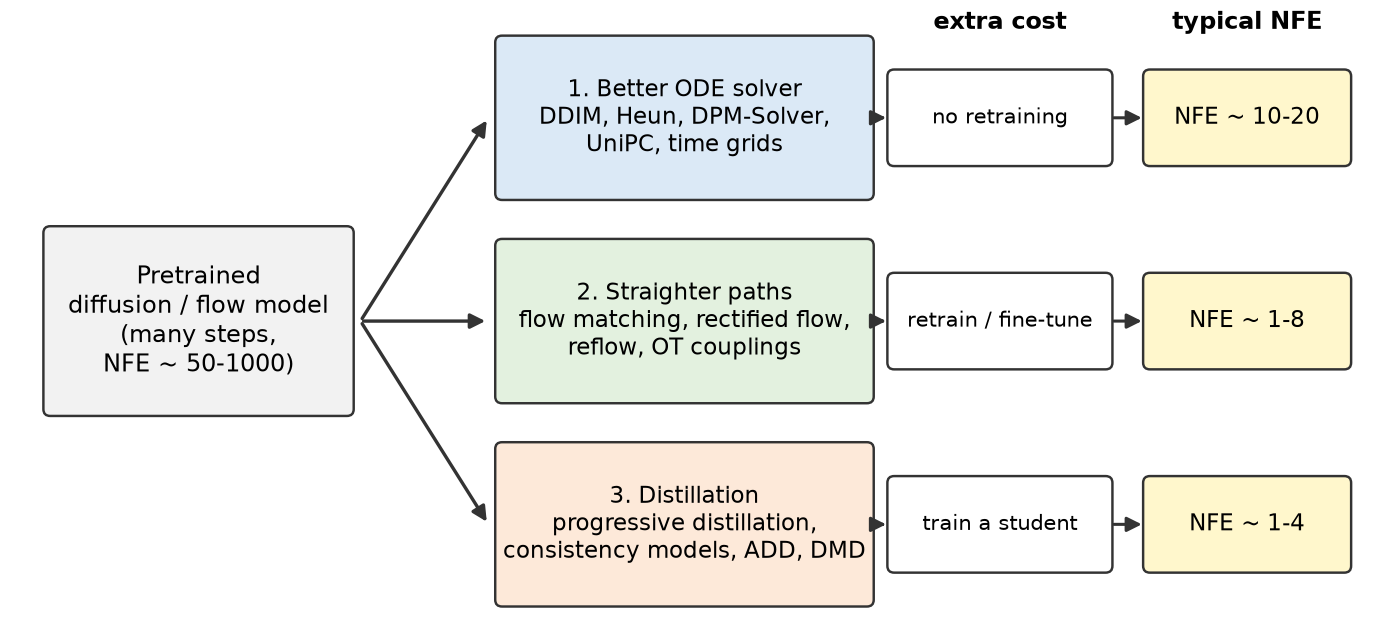

1. Лучший решатель. Обученная модель задаёт векторное поле, и генерация сводится к численному решению ОДУ. Чем точнее решатель на крупном шаге, тем меньше шагов нужно. Переобучать ничего не надо (разделы 2–3).
2. Прямее траектории. Решатель ошибается тем сильнее, чем больше искривлена траектория. Если обучить модель, у которой траектории почти прямые, хватит даже одного шага Эйлера. Это делают flow matching с линейным путём, rectified flow и reflow (разделы 4–5).
3. Дистилляция. Многошаговую модель-учителя используют для обучения ученика, который делает то же самое за 1–4 шага. Сюда относятся progressive distillation, consistency models, ADD и DMD (раздел 6).

Пути комбинируются. Например, InstaFlow сначала выпрямляет траектории Stable Diffusion через reflow, а затем дистиллирует результат в одношаговую модель ([Liu et al., 2023](https://arxiv.org/abs/2309.06380)).

## 2. ODE-формулировка и DDIM

### 2.1. Гауссов путь и probability flow ODE

Пусть зашумление задано как $x_t = \alpha_t x_0 + \sigma_t \epsilon$, где $\alpha_0 = 1, \sigma_0 = 0$ и $\alpha_1 \approx 0, \sigma_1 \approx 1$. Song et al. показали, что у каждого такого процесса есть детерминированное ОДУ — probability flow ODE. Его решения имеют те же маргинальные распределения $p_t$, что и стохастический процесс ([Song et al., 2021](https://arxiv.org/abs/2011.13456)). Для гауссова пути ОДУ удобно записать через предсказание шума $\hat\epsilon(x_t, t) = \mathbb E[\epsilon \mid x_t]$:
$
\frac{dx_t}{dt} \;=\; \frac{\dot\alpha_t}{\alpha_t}\,x_t \;+\; \Big(\dot\sigma_t - \sigma_t\frac{\dot\alpha_t}{\alpha_t}\Big)\hat\epsilon(x_t, t)
\;=\; \frac{\dot\alpha_t}{\alpha_t}\,x_t \;-\; \sigma_t\,\dot\lambda_t\,\hat\epsilon(x_t, t),
\qquad \lambda_t = \log\frac{\alpha_t}{\sigma_t}.
$
Проверка: подставим $x_t = \alpha_t x_0 + \sigma_t\epsilon$ с фиксированными $x_0, \epsilon$ и $\hat\epsilon = \epsilon$. Получим $\dot x_t = \dot\alpha_t x_0 + \dot\sigma_t \epsilon$, то есть производную самого пути. Для настоящей модели в правой части стоит условное среднее $\hat\epsilon$, а не конкретный $\epsilon$; почему этого достаточно для правильных маргиналов, объясняет раздел 4.3. Связь со score такая: $\nabla_x \log p_t(x) = -\hat\epsilon(x, t)/\sigma_t$.

Генерация — это решение ОДУ от $t = 1$ (шум) до $t = 0$. Каждое вычисление правой части стоит одного вызова сети.

### 2.2. DDIM как детерминированный сэмплер

DDIM ([Song, Meng & Ermon, 2020](https://arxiv.org/abs/2010.02502)) делает шаг от $t$ к $s < t$ так:
$
\hat x_0 = \frac{x_t - \sigma_t \hat\epsilon}{\alpha_t},\qquad x_s = \alpha_s\,\hat x_0 + \sigma_s\,\hat\epsilon .
$
Интуиция: оценить чистое изображение и шум, а затем снова смешать их, но уже в пропорции уровня $s$. Если поделить на $\sigma_s$, шаг DDIM переписывается как точный шаг Эйлера для $x/\sigma$ в переменной $\alpha/\sigma = e^{\lambda}$:
$
\frac{x_s}{\sigma_s} = \frac{x_t}{\sigma_t} + \Big(\frac{\alpha_s}{\sigma_s} - \frac{\alpha_t}{\sigma_t}\Big)\hat x_0 .
$
Отсюда два вывода. Во-первых, DDIM — метод первого порядка: его глобальная ошибка $O(h)$. Во-вторых, линейная часть ОДУ интегрируется точно, приближается только нелинейная часть. Это частный случай экспоненциального интегратора ([Lu et al., 2022](https://arxiv.org/abs/2206.00927)).

### 2.3. Для линейного пути DDIM — это метод Эйлера

Для пути $\alpha_t = 1 - t,\ \sigma_t = t$ ОДУ из 2.1 принимает вид $dx/dt = \hat\epsilon - \hat x_0 =: v(x_t, t)$: правая часть — это ожидаемая скорость $\epsilon - x_0$. Параметризации связаны так:
$
\hat x_0 = x_t - t\,v,\qquad \hat\epsilon = x_t + (1 - t)\,v .
$
Подставим это в шаг DDIM: $x_s = (1 - s)(x_t - t v) + s(x_t + (1 - t)v) = x_t + (s - t)\,v$. Это ровно шаг Эйлера. Значит, для flow-matching модели с линейным путём «DDIM» и «Euler» — одно и то же.

Для другого расписания, например VP-cosine из улучшенного DDPM, DDIM тоже совпадает с Эйлером, но на перенесённой сетке. Сделаем замену $\tau = \sigma_t/(\alpha_t + \sigma_t)$ и $\tilde x = x_t/(\alpha_t + \sigma_t)$. Тогда $\tilde x = (1 - \tau)x_0 + \tau\epsilon$ — линейный путь. Шаг DDIM инвариантен к такой замене масштаба, поэтому DDIM с любым гауссовым расписанием совпадает с Эйлером для линейного пути на неравномерной сетке $\tau_i$. Расписания отличаются только расположением узлов. В разделе 9.3 это проверено численно: разница порядка $10^{-13}$.

### 2.4. DDIM с параметром $\eta$ и связь с SDE

DDIM определяет семейство сэмплеров:
$
x_s = \alpha_s \hat x_0 + \sqrt{\sigma_s^2 - c^2}\;\hat\epsilon + c\, z,\qquad c = \eta\,\tilde\sigma_{t\to s},\quad z \sim \mathcal N(0, I),
$
где $\tilde\sigma_{t\to s}$ — стандартное отклонение апостериорного распределения $q(x_s \mid x_t, x_0)$. При $\eta = 0$ получается детерминированный DDIM (ODE), при $\eta = 1$ — DDPM-подобный стохастический сэмплер (дискретизация обратной SDE). Стохастические сэмплеры «забывают» часть накопленной ошибки за счёт свежего шума, но сами вносят ошибку, которая убывает с ростом числа шагов медленнее. Поэтому на малом бюджете обычно выигрывают ODE-решатели, а SDE-сэмплеры догоняют их при большом числе шагов ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)). Детерминированность даёт и практическое преимущество: один и тот же шум $x_1$ всегда отображается в одно и то же изображение. Это нужно для интерполяции, инверсии и дистилляции.

## 3. Решатели высокого порядка

### 3.1. Порядок точности

Решатель имеет порядок $p$, если глобальная ошибка при шаге $h$ убывает как $O(h^p)$. Удвоение числа шагов уменьшает ошибку Эйлера ($p = 1$) примерно вдвое, а ошибку метода второго порядка — вчетверо. Метод Хойна (Heun) — это шаг Эйлера плюс коррекция средним наклоном:
$
\tilde x_s = x_t + (s - t)\,v(x_t, t),\qquad x_s = x_t + \tfrac{s - t}{2}\big(v(x_t, t) + v(\tilde x_s, s)\big).
$
Он стоит двух вызовов сети на шаг. EDM использует Heun и пропускает коррекцию на последнем шаге, поэтому $n$ шагов дают $2n - 1$ вызовов ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)). Порядок метода — асимптотическое свойство. На очень крупных шагах, когда $h$ сравним с масштабом изменения поля, он не проявляется. Именно поэтому при равном NFE Heun на малых бюджетах иногда не лучше Эйлера.

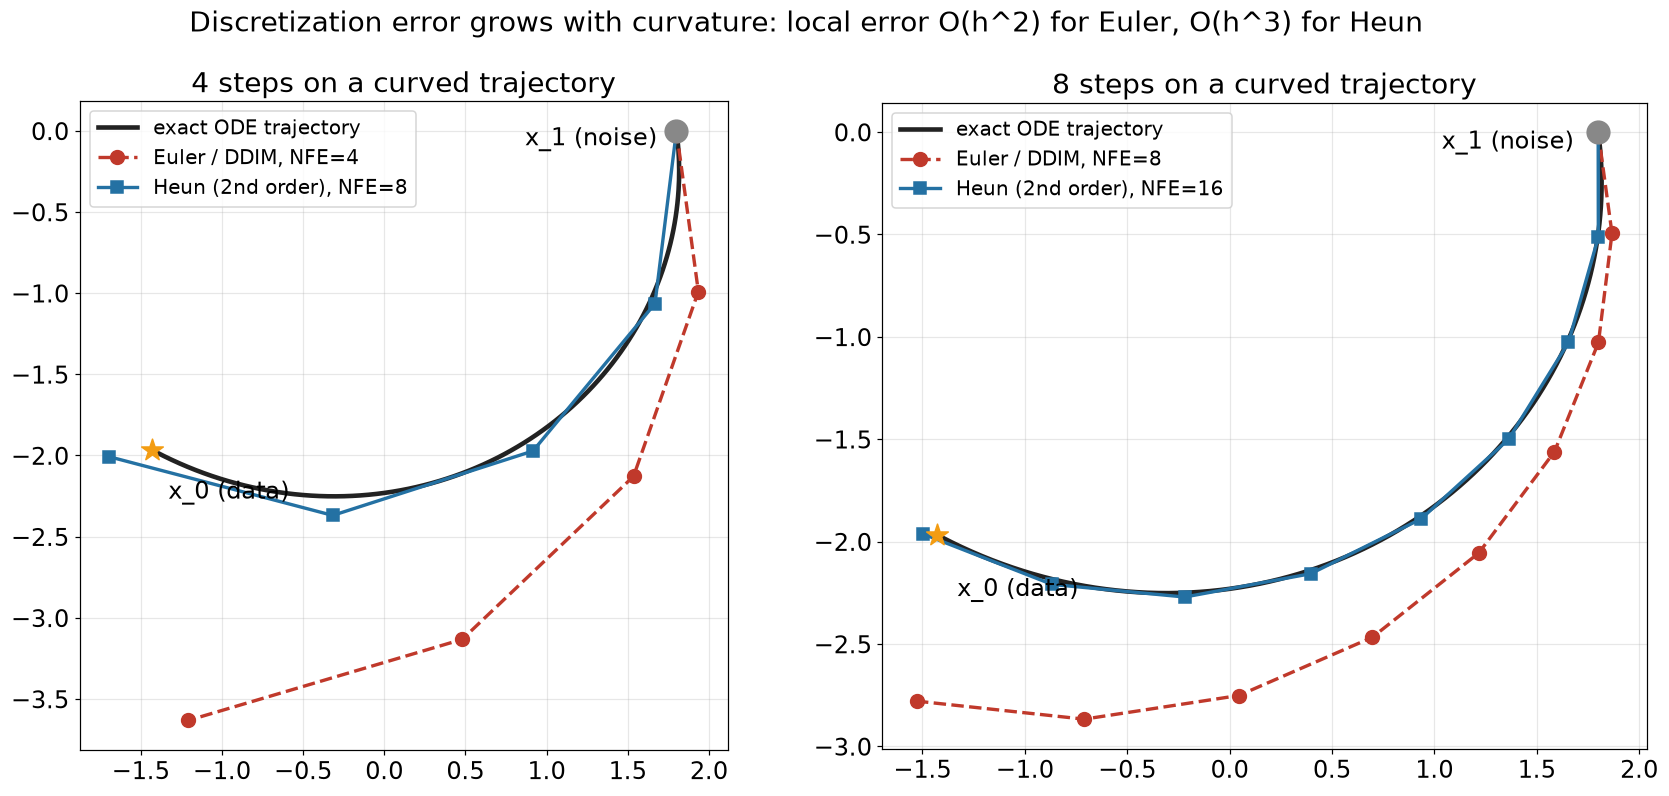

### 3.2. DPM-Solver: экспоненциальный интегратор в $\lambda$

DPM-Solver переписывает ОДУ в переменной $\lambda$ и решает линейную часть точно ([Lu et al., 2022](https://arxiv.org/abs/2206.00927)):
$
x_s = \frac{\alpha_s}{\alpha_t}x_t - \sigma_s\int_{\lambda_t}^{\lambda_s} e^{-(\lambda - \lambda_s)}\ \hat\epsilon(x_\lambda, \lambda)\, d\lambda .
$
Приближать нужно только интеграл. Если считать $\hat\epsilon$ постоянным, получается DDIM. Если приблизить $\hat\epsilon$ многочленом Тейлора первого или второго порядка по $\lambda$, получаются DPM-Solver-2 и DPM-Solver-3. По данным авторов, это даёт FID 4,70 на CIFAR-10 за 10 вызовов и 2,87 за 20, что в 4–16 раз быстрее предыдущих бестренировочных сэмплеров.

### 3.3. DPM-Solver++(2M) и UniPC

DPM-Solver++ интегрирует ту же формулу, но через предсказание данных $\hat x_0$ ([Lu et al., 2022b](https://arxiv.org/abs/2211.01095)):
$
x_s = \frac{\sigma_s}{\sigma_t}x_t + \alpha_s\big(1 - e^{-h}\big)\,D,\qquad h = \lambda_s - \lambda_t > 0 .
$
У одношагового варианта $D = \hat x_0(x_t)$, и это снова DDIM. Многошаговый вариант 2M не тратит лишних вызовов. Он экстраполирует $\hat x_0$ по двум последним шагам:
$
D = \Big(1 + \frac{1}{2r}\Big)\hat x_0^{(i)} - \frac{1}{2r}\,\hat x_0^{(i-1)},\qquad r = \frac{h_{i-1}}{h_i}.
$
Получается второй порядок при одном вызове на шаг. Параметризация через $\hat x_0$ устойчивее при большой силе guidance: $\hat x_0$ ограничен диапазоном данных, а $\hat\epsilon$, умноженный на guidance, может «улетать». Авторы получают качественные guided-образцы за 15–20 шагов, тогда как DDIM обычно нужно 100–250.

UniPC добавляет к любому многошаговому предиктору корректор UniC. Корректор использует уже сделанный вызов сети в новой точке, поэтому повышает порядок точности без дополнительных вызовов ([Zhao et al., 2023](https://arxiv.org/abs/2302.04867)). При 10 NFE это даёт FID 3,87 на CIFAR-10.

### 3.4. Сетки времени

Порядок решателя говорит, как ошибка убывает при равномерном измельчении. Не менее важно, где поставить узлы. Ошибка шага пропорциональна кривизне траектории, а она сильно различается при разных $t$. EDM ставит узлы по степенному закону по $\sigma$ ($\rho = 7$), сгущая их у данных ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)). DPM-Solver ставит узлы равномерно по $\lambda$. Для flow-моделей часто используют сдвиг $t \mapsto \frac{a t}{1 + (a - 1)t}$: при $a > 1$ больше шагов приходится на высокий шум. Такой сдвиг применяется, например, в Stable Diffusion 3 ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)).

Замечание о DPM-Solver++ на равномерной сетке по $t$. Возле $t = 1$ и $t = 0$ переменная $\lambda$ уходит в бесконечность, поэтому крайние шаги в $\lambda$ очень длинные. В разделе 9.2 видно, что из-за этого ошибка выходит на плато.

### 3.5. Predictor-corrector

В SDE-формулировке Song et al. предложили схему predictor-corrector ([Song et al., 2021](https://arxiv.org/abs/2011.13456)). Предиктор — шаг численного решателя обратной SDE. Корректор — несколько шагов динамики Ланжевена на текущем уровне шума: $x \leftarrow x + \delta\,\nabla \log p_s(x) + \sqrt{2\delta}\,z$. Корректор возвращает $x$ на правильное маргинальное распределение, но каждый его шаг стоит дополнительного вызова сети. При фиксированном NFE это почти всегда проигрыш по сравнению с тем, чтобы просто сделать вдвое больше шагов хорошего решателя. Корректор оправдан, когда сеть дешёвая или нужна именно стохастическая выборка. Корректор UniC из раздела 3.3 — другая идея с тем же названием: это детерминированная поправка порядка точности, а не шаг Ланжевена.

## 4. Flow matching

Flow matching задаёт генеративную модель сразу как ОДУ. Модель учится выдавать векторное поле, а не score. Траектории не обязаны быть путями диффузии, их выбирает разработчик ([Lipman et al., 2023](https://arxiv.org/abs/2210.02747); [Liu et al., 2023](https://arxiv.org/abs/2209.03003); [Albergo & Vanden-Eijnden, 2023](https://arxiv.org/abs/2209.15571)).

### 4.1. Непрерывный нормализующий поток и уравнение непрерывности

Векторное поле $u_t(x)$ задаёт поток $\dot x_t = u_t(x_t)$. Если $x_1 \sim p_1$, то при интегрировании от 1 к 0 распределение $p_t$ точки $x_t$ подчиняется уравнению непрерывности:
$
\partial_t p_t(x) + \nabla\cdot\big(p_t(x)\,u_t(x)\big) = 0 .
$
Говорят, что поле $u_t$ порождает путь вероятностей $p_t$. Такая модель называется continuous normalizing flow (CNF). Классические CNF обучались максимизацией правдоподобия: нужно было интегрировать ОДУ и след якобиана внутри каждого шага обучения ([Chen et al., 2018](https://arxiv.org/abs/1806.07366)). Это очень дорого. Flow matching обучает CNF без симуляции ОДУ.

### 4.2. Условные пути вероятностей

Идея: задать путь $p_t$ не напрямую, а как смесь простых условных путей. Возьмём пару $(x_0, x_1)$, $x_0 \sim p_{\text{data}}$, $x_1 \sim \mathcal N(0, I)$, и прямую между ними:
$
x_t = (1 - t)\,x_0 + t\,x_1,\qquad u_t(x_t \mid x_0, x_1) = \frac{d x_t}{dt} = x_1 - x_0 .
$
Условное поле постоянно вдоль прямой. Маргинальный путь $p_t(x) = \int p_t(x \mid x_0, x_1)\, dq(x_0, x_1)$ порождается маргинальным полем — условным средним скоростей всех прямых, проходящих через точку $x$ в момент $t$:
$
u_t(x) = \mathbb E\big[x_1 - x_0 \mid x_t = x\big].
$
Это следует из линейности уравнения непрерывности по паре $(p, pu)$. Если каждый условный путь удовлетворяет своему уравнению, то и их смесь удовлетворяет уравнению с полем, равным взвешенному среднему условных полей. У Lipman et al. условный путь гауссов: $\mathcal N\big(t x_1 + (1 - t)x_0,\ \sigma_{\min}^2\big)$. При $\sigma_{\min} \to 0$ он переходит в прямую выше. Этот путь авторы называют OT-путём: для одной пары точек он совпадает с оптимальным транспортом.

### 4.3. Почему условная потеря правильная

Маргинальное поле $u_t(x)$ неизвестно: в нём интеграл по всем данным. Поэтому прямая регрессия $\mathcal L_{\text{FM}} = \mathbb E_{t, x_t}\|v_\theta(x_t, t) - u_t(x_t)\|^2$ недоступна. Вместо неё обучают conditional flow matching:
$
\mathcal L_{\text{CFM}}(\theta) = \mathbb E_{t,\,x_0,\,x_1}\big\|v_\theta(x_t, t) - (x_1 - x_0)\big\|^2 .
$
Утверждение: $\nabla_\theta \mathcal L_{\text{CFM}} = \nabla_\theta \mathcal L_{\text{FM}}$. Раскроем квадрат в обеих потерях. Член $\|v_\theta\|^2$ у них одинаковый. Перекрёстный член:
$
\mathbb E_{x_0, x_1}\langle v_\theta(x_t, t),\, x_1 - x_0\rangle = \mathbb E_{x_t}\big\langle v_\theta(x_t, t),\, \mathbb E[x_1 - x_0 \mid x_t]\big\rangle = \mathbb E_{x_t}\langle v_\theta(x_t, t),\, u_t(x_t)\rangle .
$
Оставшиеся члены от $\theta$ не зависят. Значит, потери отличаются на константу, и минимизатор CFM — это маргинальное поле. Аргумент тот же, что и в denoising score matching: регрессия на шумную цель сходится к её условному среднему. Отсюда следствие: минимум $\mathcal L_{\text{CFM}}$ не равен нулю. Остаток — это условная дисперсия $\mathbb E\,\|x_1 - x_0 - u_t(x_t)\|^2$. Он велик там, где через одну точку проходят прямые с разными направлениями.

### 4.4. Связь с диффузией

Линейный путь — это гауссов путь с $\alpha_t = 1 - t,\ \sigma_t = t$. Значит, flow-matching модель одновременно является диффузионной моделью, и к ней применимы все решатели из разделов 2–3. Параметризации переводятся так:
$
\hat x_0 = x_t - t\,v,\qquad \hat\epsilon = x_t + (1 - t)\,v,\qquad \nabla_x\log p_t(x) = -\frac{\hat\epsilon}{t} .
$
Обратно, любую $\epsilon$-модель можно превратить в поле скорости. Kingma & Gao показали, что потери диффузионных моделей с разными параметризациями и весами по шуму являются взвешенными ELBO ([Kingma & Gao, 2023](https://arxiv.org/abs/2303.00848)). Flow matching с линейным путём — одна из точек этого семейства. Её отличают выбор пути (прямые) и то, как распределены $t$ при обучении. Stable Diffusion 3 обучает rectified flow с распределением $t$, смещённым к средним уровням шума ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)).

## 5. Rectified flow и выпрямление траекторий

### 5.1. Почему маргинальные траектории искривлены

Каждая условная траектория — прямая. Но маргинальное поле усредняет направления всех прямых, проходящих через точку. Когда пары $(x_0, x_1)$ независимы, прямые пересекаются. Например, шум из центра может соответствовать любой моде данных. Траектории ОДУ пересекаться не могут, и в точках пересечения поле усредняется. Поэтому траектории маргинального потока не пересекаются, но изгибаются. На рисунке ниже в одномерном примере это видно хорошо: среднее поле сначала ведёт точки к среднему, а затем они расходятся к модам.

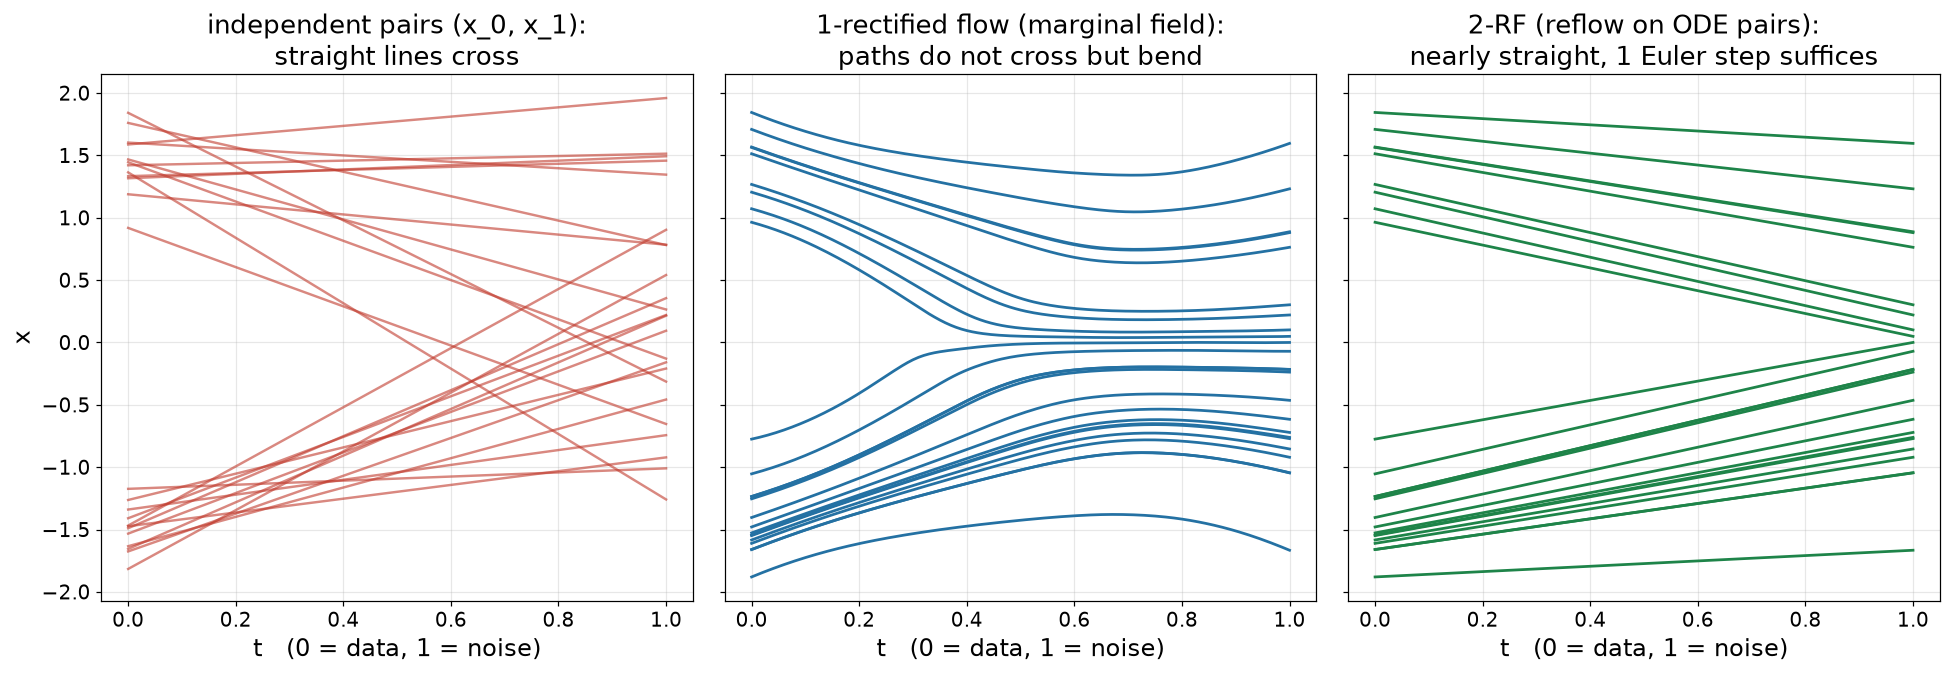

### 5.2. Reflow и мера прямолинейности

Liu et al. называют поток, обученный CFM на независимой связке, 1-rectified flow ([Liu et al., 2023](https://arxiv.org/abs/2209.03003)). Reflow выглядит так:

1. сгенерировать пары $(x_0, x_1)$, решая ОДУ 1-RF от шума $x_1$ до образца $x_0 = \Phi(x_1)$;
2. обучить новую модель CFM на этих детерминированных парах вместо независимых. Получится 2-RF.

У новых пар прямые почти не пересекаются: пары уже были соединены траекториями ОДУ, которые не пересекаются. Поэтому условная дисперсия мала, маргинальное поле почти совпадает с $x_1 - x_0$, и траектории 2-RF почти прямые. Авторы доказывают два свойства. Во-первых, маргиналы сохраняются: 2-RF переводит $p_1$ в то же распределение данных. Во-вторых, для любой выпуклой стоимости $c$ транспортная стоимость $\mathbb E\,c(x_1 - x_0)$ не растёт.

Мера искривлённости траекторий:
$
S(v) = \int_0^1 \mathbb E\,\big\|(x_1 - x_0) - v(x_t, t)\big\|^2\, dt ,
$
где $x_t$ — точки траектории ОДУ, а $x_0, x_1$ — её концы. $S = 0$ означает, что все траектории — прямые с постоянной скоростью. Для такого потока один шаг Эйлера точен: $x_0 = x_1 - v(x_1, 1)$. Каждый reflow уменьшает $S$, но генерация пар стоит дорого, а ошибки обучения накапливаются. Обычно делают один-два раунда.

### 5.3. Варианты: InstaFlow, OT-связки, SD3

- InstaFlow применяет reflow к Stable Diffusion и затем дистиллирует 2-RF в одношаговую модель. Результат: FID 23,3 на MS COCO 2017-5k при 0,09 с на изображение и 199 A100 GPU-днях обучения ([Liu et al., 2023b](https://arxiv.org/abs/2309.06380)).
- Пары можно сделать менее пересекающимися ещё при первом обучении. Для этого внутри мини-батча шум сопоставляют данным решением задачи оптимального транспорта (minibatch OT-CFM). Получаются более простые потоки, обучение стабильнее, а вывод быстрее ([Tong et al., 2023](https://arxiv.org/abs/2302.00482)).
- Stable Diffusion 3 обучает rectified flow-трансформер без reflow. Скорость там достигается подбором распределения $t$ и масштабированием модели ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)).

## 6. Дистилляция

Дистилляция обучает быструю модель-ученика воспроизводить отображение «шум → образец», которое задаёт многошаговый учитель. Подходы различаются тем, какую цель видит ученик.

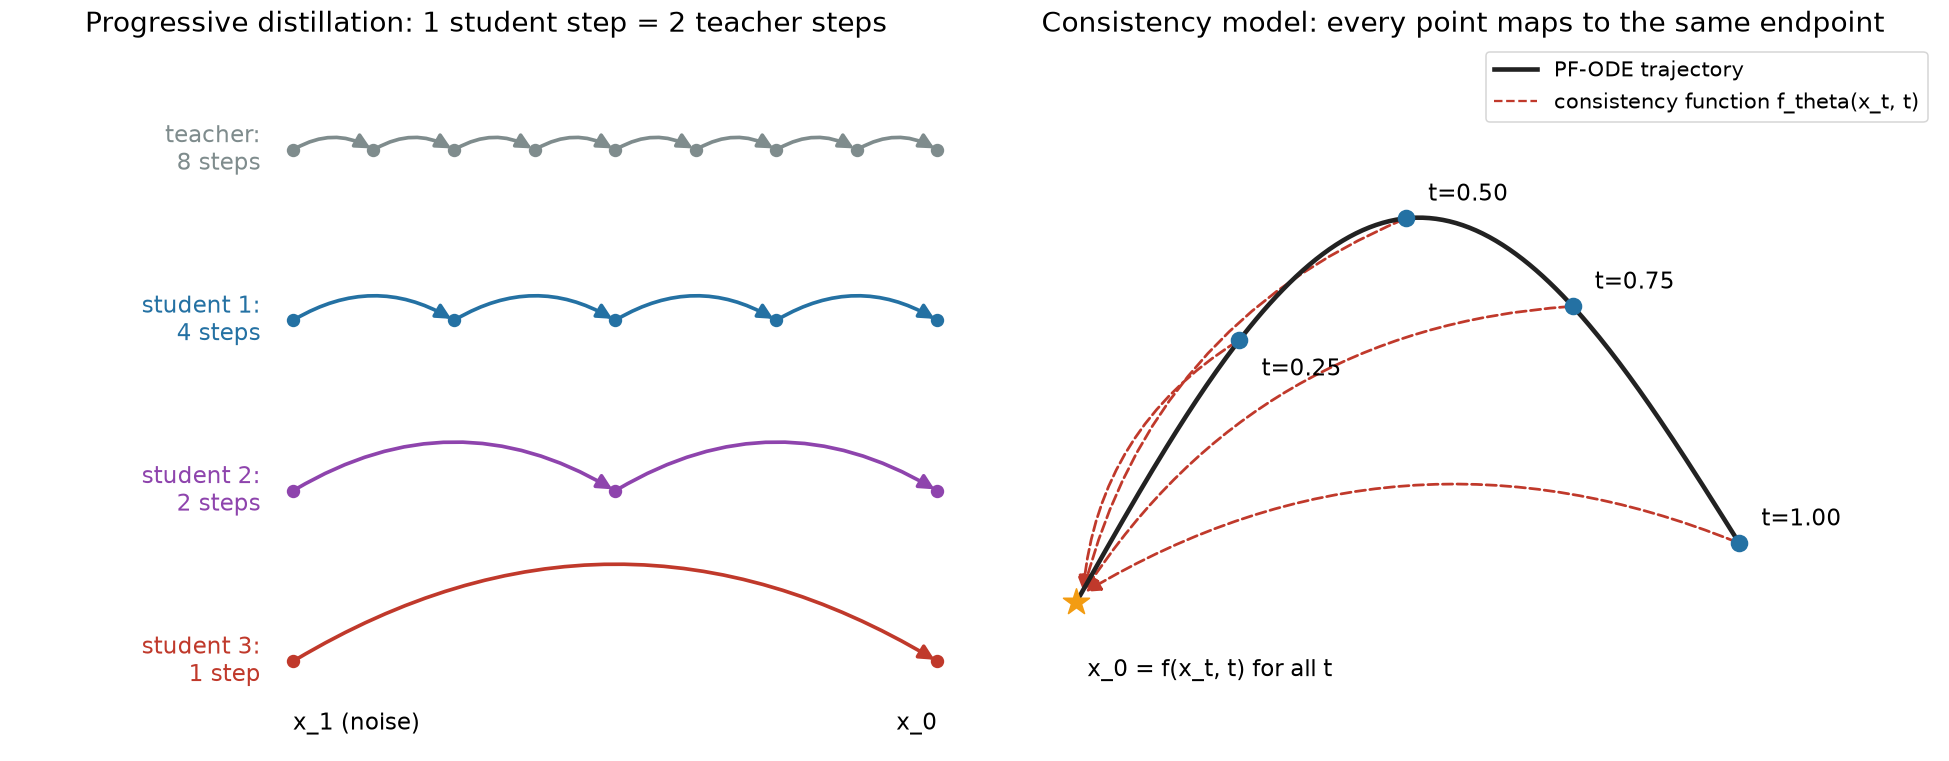

### 6.1. Прямая дистилляция

Самый прямой способ — сгенерировать учителем много пар (шум, образец) и регрессией обучить одношаговую сеть $x_1 \mapsto x_0$. Так сделали Luhman & Luhman: их Denoising Student сопоставим с GAN на CIFAR-10 и CelebA ([Luhman & Luhman, 2021](https://arxiv.org/abs/2101.02388)). Недостатки: нужен большой датасет пар, каждая пара стоит полной генерации учителем, а регрессия на L2 «размывает» результат там, где отображение сложное. 2-RF из раздела 5.2 обучается на тех же парах, но предсказывает поле, а не сразу результат, и затем может использовать несколько шагов.

### 6.2. Progressive distillation

Salimans & Ho предложили дистиллировать постепенно ([Salimans & Ho, 2022](https://arxiv.org/abs/2202.00512)). Ученик, инициализированный весами учителя, учится одним шагом повторять два шага учителя. Потом ученик становится учителем, и число шагов снова уменьшается вдвое: $N \to N/2 \to \dots \to 1$. Цель на каждом шаге обучения дешёвая — два вызова учителя из случайной точки $x_t$ настоящих данных. Пары на всю траекторию генерировать не нужно. Авторы начинали с 8192 шагов и дошли до 4 при FID 3,0 на CIFAR-10. Для DDIM цель записывается в замкнутом виде. Если учитель из $x_t$ за два шага пришёл в $x_s$, ученик должен предсказать $\tilde x_0$, из которого один шаг DDIM даёт тот же $x_s$. Для линейного пути это просто средняя скорость $(x_t - x_s)/(t - s)$ (раздел 14). Минусы: число раундов растёт как $\log_2 N$, а ошибки раундов накапливаются.

### 6.3. Consistency models

Consistency model ([Song et al., 2023](https://arxiv.org/abs/2303.01469)) учит consistency-функцию $f_\theta(x_t, t)$. Она отображает любую точку траектории PF-ODE в её конец $x_0$. Отсюда свойство самосогласованности: $f(x_t, t) = f(x_{t'}, t')$ для точек одной траектории. Граничное условие $f(x, 0) = x$ встраивают в параметризацию. В этой лекции $f_\theta(x, t) = x - t\,F_\theta(x, t)$, то есть при $t = 0$ условие выполняется автоматически. При обучении consistency distillation (CD) берётся сетка $0 = t_0 < \dots < t_N = 1$:

1. взять $x_0$ из данных, номер $n$ и точку $x_{t_{n+1}} = (1 - t_{n+1})x_0 + t_{n+1}\epsilon$;
2. сделать один шаг учителя-решателя к соседней точке: $\hat x_{t_n} = \text{Solver}(x_{t_{n+1}};\ t_{n+1} \to t_n)$;
3. минимизировать $d\big(f_\theta(x_{t_{n+1}}, t_{n+1}),\ f_{\theta^-}(\hat x_{t_n}, t_n)\big)$, где $\theta^-$ — EMA весов ученика, а градиент через цель не идёт.

Цель для точки на шаге $n + 1$ — это предсказание самого ученика на шаге $n$, который ближе к данным. Правильность «протекает» от $t = 0$, где $f$ задана граничным условием, к большим $t$. В исходной статье на CIFAR-10 используются $N = 18$ и $\mu = 0{,}95$. Результат: FID 3,55 на CIFAR-10 и 6,20 на ImageNet 64 за один шаг. Многошаговая генерация чередует $x_0 = f(x_\tau, \tau)$ и повторное зашумление до меньшего $\tau$. Каждый дополнительный шаг стоит одного вызова сети.

### 6.4. Consistency training и потомки

- Consistency training (CT) обходится без учителя. Вместо $\hat x_{t_n}$ берётся точка $x_{t_n}$ с тем же $\epsilon$, что и у $x_{t_{n+1}}$. При $N \to \infty$ такая цель эквивалентна consistency distillation ([Song et al., 2023](https://arxiv.org/abs/2303.01469)).
- В improved CT отказались от EMA в целевой сети, заменили LPIPS на псевдо-Хьюбер $\sqrt{\|a - b\|^2 + c^2} - c$ и постепенно увеличивают $N$ ([Song & Dhariwal, 2023](https://arxiv.org/abs/2310.14189)). Результаты: FID 2,51 на CIFAR-10 и 3,25 на ImageNet 64 за один шаг, 2,24 и 2,77 за два.
- sCM перешёл к непрерывному времени и масштабировал CM до 1,5 млрд параметров. За два шага получено FID 2,06 на CIFAR-10, 1,48 на ImageNet 64 и 1,88 на ImageNet 512 ([Lu & Song, 2024](https://arxiv.org/abs/2410.11081)).
- Latent Consistency Models дистиллируют Stable Diffusion с guidance в латентном пространстве. Модель на 768×768 работает за 2–4 шага, а обучение стоит 32 A100 GPU-часа ([Luo et al., 2023](https://arxiv.org/abs/2310.04378)).

### 6.5. Дистилляция распределения и guidance

- ADD сочетает score distillation от большой диффузионной модели с адверсариальной потерей. Модель делает 1–4 шага и за четыре шага достигает качества SDXL ([Sauer et al., 2023](https://arxiv.org/abs/2311.17042)).
- DMD сопоставляет распределение одношагового генератора с распределением учителя: минимизирует приближённую KL-дивергенцию, градиент которой равен разности двух score-функций. Результаты: FID 2,62 на ImageNet 64 и 11,49 на COCO-30k при 20 кадрах в секунду ([Yin et al., 2024](https://arxiv.org/abs/2311.18828)).
- Classifier-free guidance удваивает NFE: на каждом шаге нужны условный и безусловный вызовы. Meng et al. сначала дистиллируют guided-модель в одну сеть, которая принимает силу guidance как вход, а затем применяют progressive distillation. Пиксельные модели работают за 4 шага и до 256 раз быстрее, латентные — за 1–4 шага и как минимум в 10 раз быстрее ([Meng et al., 2023](https://arxiv.org/abs/2210.03142)).

В практикуме модель условная по классу, но без CFG, поэтому NFE равно числу шагов.

## 7. Честное сравнение: равное NFE и Парето-фронт

### 7.1. Равное NFE

Решатель с двумя вызовами на шаг сравнивают с Эйлером не при равном числе шагов, а при равном числе вызовов сети. Heun с 5 шагами (9 NFE) сопоставим с Эйлером на 9 шагах. Многошаговые методы (DPM-Solver++ 2M, UniPC) ценны тем, что дают второй порядок при одном вызове на шаг. Дистиллированные модели сравнивают с базовой при том же NFE, причём для базовой берут лучший решатель, а не DDIM.

### 7.2. Парето-фронт «качество — время»

Каждая конфигурация (модель, решатель, число шагов) — точка на плоскости «время генерации — ошибка». Точка доминирует другую, если она не медленнее и не хуже, и строго лучше хотя бы по одной оси. Парето-фронт — множество недоминируемых точек. Сравнивать методы осмысленно только вдоль фронта: метод, лежащий выше фронта при любом времени, хуже всегда. Фронт обычно ломаный. На малом бюджете его образуют дистиллированные модели, на среднем — решатели высокого порядка, а на большом — базовая модель с мелким шагом, потому что ученик ограничен качеством учителя.

### 7.3. Что учитывать в сравнении

1. Стоимость обучения. Reflow и дистилляция требуют дополнительного обучения, а иногда и генерации пар. Ускорение окупается только после определённого числа сгенерированных изображений (раздел 16.3).
2. Метрика. FID на 50 тысячах образцов — стандарт ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)). На нескольких сотнях образцов метрика смещена и шумна, сравнивать стоит только при одинаковом размере выборки. В практикуме у FD есть «пол»: значение, которое дают настоящие изображения той же численности.
3. Время на вызов. Оно зависит от устройства, размера батча и разрешения. На GPU с большим батчем вызов сети может стоить меньше, чем на CPU, а накладные расходы решателя — оказаться заметными.
4. Разнообразие. Одношаговые ученики иногда выигрывают по точности класса или «чёткости» и проигрывают по разнообразию. Поэтому смотреть нужно на несколько метрик.

# Часть II. Практикум

## 8. Подготовка: среда, данные, модель-оценщик

### 8.1. Задача практикума

Практикум проверяет все три пути ускорения на двух масштабах. В двумерном примере (смесь гауссиан) скорость потока для линейного пути известна аналитически. Поэтому можно точно измерить ошибку каждого решателя ОДУ и увидеть, как выглядят и выпрямляются траектории. На MNIST обучаются базовая модель flow matching и три её ускоренные версии: rectified flow после reflow, progressive distillation и consistency distillation. Все они сравниваются при равном числе вызовов сети (NFE) и по времени, а в конце строится Парето-фронт «качество — время».

| Раздел | Что делаем | Что увидим |
|---|---|---|
| 8 | среда, данные, классификатор-оценщик (как в лекции 12) | FD, acc, div |
| 9 | 2D: точное поле скоростей, решатели ОДУ | порядок сходимости, DDIM = Euler |
| 10 | 2D: flow matching и reflow | пересечение условных путей, выпрямление траекторий |
| 11 | MNIST: базовая модель flow matching | кривая потерь, диффузионная и потоковая параметризации |
| 12 | MNIST: сэмплеры при малом NFE | Euler, Heun, DPM-Solver, SDE и predictor-corrector |
| 13 | MNIST: reflow | прямота траекторий и качество за 1–4 шага |
| 14 | MNIST: progressive distillation | 8 → 4 → 2 → 1 шаг |
| 15 | MNIST: consistency distillation | генерация за 1–4 шага |
| 16 | сравнение при равном NFE и Парето-фронт | какой метод лучше при данном бюджете |
| 17 | сводная таблица | всё в одних метриках |

### 8.2. Режимы запуска

В Colab с GPU (`Runtime → Change runtime type → T4 GPU`) сеть шире (32 базовых канала и два блока на уровень вместо 16 и одного), все модели обучаются в 5–6 раз дольше, а для оценки генерируется 2000 изображений. На CPU автоматически включается `FAST_DEV_RUN`: шагов обучения меньше, сеть уже, для оценки генерируется 500 изображений. Все числа в тексте практикума взяты из сохранённого CPU-прогона. На GPU значения будут другими (как правило, лучше), поэтому переносить стоит направление эффектов, а не сами числа. GPU-путь не проверялся.

In [1]:
import os, io, math, time, random, platform, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from scipy import linalg

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FAST_DEV_RUN = DEVICE == "cpu"
torch.set_num_threads(max(1, os.cpu_count() or 1))
T_START = time.time()

S = dict(  # шаги оптимизатора, размеры сети и оценочных выборок
    bs=128, steps_cls=800, steps_2d=6000, steps_reflow_2d=3000, ch=32, mult=(1, 2, 2), n_res=2,
    steps_base=15000, n_pairs=20000, steps_reflow=4000, steps_pd=1500, pd_start=16, steps_cd=6000, n_eval=2000)
if FAST_DEV_RUN:
    S.update(bs=64, steps_2d=3000, steps_reflow_2d=1500, ch=16, mult=(1, 2, 4), n_res=1,
             steps_base=2000, n_pairs=6000, steps_reflow=600, steps_pd=250, pd_start=8, steps_cd=800, n_eval=500)

def seed_all(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all(0)

print("python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__)
print("device:", DEVICE, "| FAST_DEV_RUN:", FAST_DEV_RUN, "| threads:", torch.get_num_threads())
print(S)

python 3.12.13 | torch 2.14.1+cpu | torchvision 0.29.1+cpu
device: cpu | FAST_DEV_RUN: True | threads: 2
{'bs': 64, 'steps_cls': 800, 'steps_2d': 3000, 'steps_reflow_2d': 1500, 'ch': 16, 'mult': (1, 2, 4), 'n_res': 1, 'steps_base': 2000, 'n_pairs': 6000, 'steps_reflow': 600, 'steps_pd': 250, 'pd_start': 8, 'steps_cd': 800, 'n_eval': 500}


### 8.3. Данные

MNIST: 60 000 обучающих и 10 000 тестовых изображений 28×28, значения переводятся в $[-1, 1]$, как в лекции 12. Функции `to_m1` и `to_01` переводят $[0, 1]$ в $[-1, 1]$ и обратно.

In [2]:
tr = torchvision.datasets.MNIST("data", train=True, download=True)
te = torchvision.datasets.MNIST("data", train=False, download=True)
def to_tensor(ds):
    return ds.data.float().div(255).unsqueeze(1), ds.targets.clone()
Xtr, Ytr = to_tensor(tr); Xte, Yte = to_tensor(te)
to_m1 = lambda x: x * 2 - 1
to_01 = lambda x: ((x + 1) / 2).clamp(0, 1)
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))

def batches(X, Y, bs, steps, seed=0):
    g = torch.Generator().manual_seed(seed)
    for _ in range(steps):
        i = torch.randint(0, len(X), (bs,), generator=g)
        yield X[i].to(DEVICE), Y[i].to(DEVICE)

def show(imgs, nrow=10, title=None, scale=1.0):
    imgs = imgs.detach().float().cpu().clamp(0, 1)
    ncol = math.ceil(len(imgs) / nrow)
    grid = torchvision.utils.make_grid(imgs, nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(scale * nrow * 0.62, scale * ncol * 0.62 + (0.5 if title else 0)))
    plt.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray"); plt.axis("off")
    if title: plt.title(title, fontsize=15)
    plt.tight_layout(); plt.show()

class Timer:
    def __enter__(self):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        self.t = time.time(); return self
    def __exit__(self, *a):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        self.s = time.time() - self.t

train (60000, 1, 28, 28) test (10000, 1, 28, 28)


### 8.4. Классификатор-оценщик и метрики генерации

Генеративные модели сравниваются тремя числами. Все три считает один маленький классификатор, обученный на реальных данных.

- FD (Fréchet distance) — расстояние Фреше между гауссианами, подогнанными к признакам реальных и сгенерированных изображений. Формула та же, что у FID ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)), но признаки берутся из нашего классификатора, а не из Inception. Числа несравнимы с FID из статей, но сравнимы между моделями блокнота. Меньше — лучше.
- Точность класса (acc) — доля изображений, которые классификатор относит к запрошенному классу. Это мера соответствия условию (fidelity в смысле условной генерации).
- Разнообразие (div) — средняя попарная дистанция признаков внутри класса, делённая на ту же величину для реальных изображений. Значение 1 — «разнообразно, как реальные данные», около 0 — «одно и то же изображение».

Вспомогательная величина — уверенность классификатора (conf, средняя максимальная вероятность): неразборчивые цифры дают низкую уверенность.

In [3]:
class Clf(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Linear(128, 10)
    def forward(self, x): return self.head(self.f(x))

seed_all(0)
clf = Clf().to(DEVICE); opt = torch.optim.Adam(clf.parameters(), 2e-3)
with Timer() as t:
    for x, y in batches(Xtr, Ytr, S["bs"], S["steps_cls"], seed=1):
        loss = F.cross_entropy(clf(x), y); opt.zero_grad(); loss.backward(); opt.step()
clf.eval().requires_grad_(False)

@torch.no_grad()
def clf_out(x, bs=500):
    fs, ps = [], []
    for i in range(0, len(x), bs):
        xb = x[i:i + bs].to(DEVICE).float().clamp(0, 1)
        f = clf.f(xb); fs.append(f.cpu()); ps.append(clf.head(f).softmax(-1).cpu())
    return torch.cat(fs).double().numpy(), torch.cat(ps)

import warnings; warnings.filterwarnings("ignore", category=linalg.LinAlgWarning)

def frechet(fa, fb):
    mu1, mu2 = fa.mean(0), fb.mean(0); s1, s2 = np.cov(fa, rowvar=False), np.cov(fb, rowvar=False)
    covmean = linalg.sqrtm(s1 @ s2)
    if isinstance(covmean, tuple): covmean = covmean[0]
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean.real))

def within_class_spread(f, cls):
    vals = []
    for c in range(10):
        fc = torch.from_numpy(f[cls == c])
        if len(fc) >= 2: vals.append(torch.pdist(fc).mean().item())
    return float(np.mean(vals))

F_TE, P_TE = clf_out(Xte)
print(f"classifier: {t.s:.0f} s, test accuracy {(P_TE.argmax(1) == Yte).float().mean():.4f}")
g = torch.Generator().manual_seed(0)
REF_IDX = torch.randperm(len(Xte), generator=g)[:S["n_eval"]]
SPREAD_REAL = within_class_spread(F_TE[REF_IDX], Yte[REF_IDX].numpy())

def evaluate(x01, y=None):
    """x01 в [0, 1]. FD к 10 000 тестовых изображений, acc (если задан класс), conf, div."""
    f, p = clf_out(x01); pred = p.argmax(1)
    cls = (y.cpu() if y is not None else pred).numpy()
    r = dict(FD=frechet(f, F_TE), conf=p.max(1).values.mean().item(),
             div=within_class_spread(f, cls) / SPREAD_REAL)
    if y is not None: r["acc"] = (pred == y.cpu()).float().mean().item()
    return r

def fmt(r): return "  ".join(f"{k}={v:.3f}" if k != "FD" else f"FD={v:.2f}" for k, v in r.items())
base_real = evaluate(Xte[REF_IDX], Yte[REF_IDX])
print("real test sample:", fmt(base_real))
Y_EVAL = torch.arange(S["n_eval"]) % 10           # запрашиваемые классы при оценке: поровну каждой цифры

classifier: 25 s, test accuracy 0.9449


real test sample: FD=1.04  conf=0.926  div=1.000  acc=0.944


**Что видно.** Классификатор-оценщик за 25 с достиг точности 0,945 на тесте. Этого хватает, чтобы его признаки различали качество генерации. 500 настоящих тестовых изображений дают FD 1,04 относительно всех 10 000 тестовых. Это «пол» метрики при нашем размере выборки: ниже него генератор опуститься не может, и разницы порядка 0,1 у хороших методов лежат в пределах шума. Точность класса на настоящих изображениях 0,944, поэтому acc около 0,94–0,96 у генераторов означает уровень данных, а не недостаток модели.

## 9. Двумерный пример: решатели ОДУ на точном поле

### 9.1. Данные и точная скорость

Данные те же, что в лекции 12: смесь 8 гауссиан на окружности радиуса 1,5 со стандартным отклонением 0,1. Четыре «тяжёлые» моды имеют вес 0,2, четыре «лёгкие» — 0,05. Используем линейный путь rectified flow: $x_t = (1 - t)\,x_0 + t\,\epsilon$, где $t = 0$ — данные, $t = 1$ — шум (раздел 4). Для смеси гауссиан условное распределение $x_0$ при данном $x_t$ известно точно. Компонента $k$ даёт $x_t \sim \mathcal{N}\big((1-t)\mu_k,\ ((1-t)^2\sigma_0^2 + t^2) I\big)$ и
$
\mathbb{E}[x_0 \mid x_t, k] = \mu_k + \frac{(1-t)\,\sigma_0^2}{(1-t)^2\sigma_0^2 + t^2}\,\big(x_t - (1-t)\mu_k\big).
$
Усредняя по апостериорным весам компонент, получаем $\mathbb{E}[x_0 \mid x_t]$. Маргинальная скорость при этом равна $u_t(x) = \big(x - \mathbb{E}[x_0 \mid x_t = x]\big)/t$ (раздел 4.2). Так у нас есть точное поле, и ошибку любого решателя можно отделить от ошибки сети.

Все сэмплеры ниже написаны для одной функции `vel(x, t)`: она возвращает скорость $u$, из которой получаются оба предсказания, $\hat x_0 = x - t\,u$ и $\hat\epsilon = x + (1 - t)\,u$. Сетке времени $1 = t_0 > t_1 > \dots > t_n = 0$ соответствуют $n$ шагов:

- `euler` — шаг $x \leftarrow x + (t_{i+1} - t_i)\,u(x, t_i)$, $n$ вызовов сети (NFE). Для линейного пути это в точности DDIM (раздел 2.3);
- `heun` — метод Хойна, как в EDM ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)): шаг Эйлера, затем поправка средним двух скоростей; на последнем шаге (до $t = 0$) только Эйлер, поэтому NFE $= 2n - 1$;
- `dpmpp2m` — DPM-Solver++(2M) ([Lu et al., 2022b](https://arxiv.org/abs/2211.01095)): экспоненциальный интегратор по $\lambda = \log(\alpha/\sigma)$ с линейной экстраполяцией $\hat x_0$ по двум последним шагам, NFE $= n$. Первый и последний шаги — первого порядка: на концах $\lambda = \mp\infty$;
- `ddim_eta` — DDIM с параметром $\eta$ (раздел 2.4): $\eta = 0$ совпадает с `euler`, $\eta = 1$ — анцестральный стохастический сэмплер типа DDPM;
- `pc` — predictor-corrector ([Song et al., 2021](https://arxiv.org/abs/2011.13456)): стохастический шаг-предиктор и один шаг Ланжевена-корректор на новом уровне шума, NFE $= 2n - 1$.

In [4]:
K_MODES, R, SIG0 = 8, 1.5, 0.1
ang = torch.arange(K_MODES) * 2 * math.pi / K_MODES
MU = torch.stack([R * ang.cos(), R * ang.sin()], 1).to(DEVICE)
PI = torch.tensor([0.2, 0.05] * 4, device=DEVICE)
HEAVY = torch.arange(K_MODES, device=DEVICE) % 2 == 0

def sample_data(n, gen=None):
    k = torch.multinomial(PI, n, replacement=True, generator=gen)
    return MU[k] + SIG0 * torch.randn(n, 2, device=DEVICE, generator=gen)

def exact_vel(x, t):
    """Точная маргинальная скорость линейного пути для смеси гауссиан. t: скаляр или (B,)."""
    t = torch.as_tensor(t, dtype=x.dtype, device=x.device).expand(len(x)).view(-1, 1)
    a = 1 - t; var = a ** 2 * SIG0 ** 2 + t ** 2
    d = x[:, None, :] - a[:, None, :] * MU[None].to(x.dtype)               # (B, K, 2)
    r = (PI.log().to(x.dtype)[None] - (d ** 2).sum(-1) / (2 * var)).softmax(-1)[..., None]
    ex0 = (r * (MU[None].to(x.dtype) + (a * SIG0 ** 2 / var)[:, None, :] * d)).sum(1)
    return (x - ex0) / t

def data_logpdf(x):
    d2 = ((x[:, None, :] - MU[None]) ** 2).sum(-1)
    return torch.logsumexp(PI.log()[None] - d2 / (2 * SIG0 ** 2), -1) - math.log(2 * math.pi * SIG0 ** 2)

def sample_quality(x):
    """Средний log p_data, доля в тяжёлых модах (у данных 0,8), доля точек вне мод (дальше 4 sigma0 от центров)."""
    x = x.float(); d = ((x[:, None, :] - MU[None]) ** 2).sum(-1).sqrt(); near = d.argmin(1); off = d.min(1).values > 4 * SIG0
    return dict(logp=data_logpdf(x).clamp(min=-50).mean().item(),
                heavy=HEAVY[near[~off]].float().mean().item(), off=off.float().mean().item())

# ---------- сетки времени и сэмплеры: общий интерфейс vel(x, t) -> u ----------
def t_grid(n, shift=1.0):
    """n шагов от t = 1 до t = 0. shift > 1 сгущает шаги у шума (как в SD3), shift < 1 — у данных."""
    t = torch.linspace(1, 0, n + 1, dtype=torch.float64)
    return shift * t / (1 + (shift - 1) * t)

def _tb(x, t): return torch.full((len(x),), float(t), device=x.device, dtype=x.dtype)

@torch.no_grad()
def euler(vel, x, ts, traj=False):
    path = [x]
    for t, s in zip(ts[:-1], ts[1:]):
        x = x + (s - t) * vel(x, _tb(x, t))
        if traj: path.append(x)
    return (x, torch.stack(path)) if traj else x

@torch.no_grad()
def heun(vel, x, ts):
    for t, s in zip(ts[:-1], ts[1:]):
        d1 = vel(x, _tb(x, t)); xe = x + (s - t) * d1
        x = xe if s == 0 else x + (s - t) * 0.5 * (d1 + vel(xe, _tb(x, s)))
    return x

@torch.no_grad()
def dpmpp2m(vel, x, ts):
    """DPM-Solver++(2M) для пути alpha = 1 - t, sigma = t; lambda = log(alpha / sigma)."""
    lam = lambda t: math.log((1 - t) / t) if 0 < t < 1 else (math.inf if t == 0 else -math.inf)
    x0_prev, h_prev = None, None
    for i, (t, s) in enumerate(zip(ts[:-1].tolist(), ts[1:].tolist())):
        x0 = x - t * vel(x, _tb(x, t))
        h = lam(s) - lam(t)
        if s == 0: x = x0; break                                              # последний шаг: x_0 = x0_hat
        e_mh = s * (1 - t) / ((1 - s) * t) if t < 1 else 0.0                 # exp(-h) через отношения, без бесконечностей
        D = x0 if (x0_prev is None or not math.isfinite(h_prev)) else x0 + (h_prev / h) ** -1 / 2 * (x0 - x0_prev)
        x = (s / t) * x + (1 - s) * (1 - e_mh) * D
        x0_prev, h_prev = x0, h
    return x

@torch.no_grad()
def ddim_eta(vel, x, ts, eta=1.0, gen=None):
    """DDIM(eta) для произвольного гауссова пути: alpha = 1 - t, sigma = t."""
    for t, s in zip(ts[:-1].tolist(), ts[1:].tolist()):
        u = vel(x, _tb(x, t)); x0, eps = x - t * u, x + (1 - t) * u
        if s == 0: x = x0; break
        a_t, a_s = 1 - t, 1 - s
        var_ts = t ** 2 - (a_t / a_s) ** 2 * s ** 2                       # дисперсия перехода q(x_t | x_s)
        sig = eta * math.sqrt(max(var_ts * s ** 2 / t ** 2, 0.0))           # eta * стандартное отклонение апостериори
        x = a_s * x0 + math.sqrt(max(s ** 2 - sig ** 2, 0.0)) * eps + sig * torch.randn(x.shape, generator=gen, device=x.device, dtype=x.dtype)
    return x

@torch.no_grad()
def pc(vel, x, ts, snr=0.1, gen=None):
    """Predictor-corrector: предиктор DDIM(eta = 1), корректор — один шаг Ланжевена на новом уровне шума."""
    for t, s in zip(ts[:-1], ts[1:]):
        x = ddim_eta(vel, x, torch.stack([t, s]), eta=1.0, gen=gen)
        if s == 0: break
        u = vel(x, _tb(x, s)); score = -(x + (1 - s) * u) / s                # score = -E[eps | x] / sigma
        z = torch.randn(x.shape, generator=gen, device=x.device, dtype=x.dtype)
        step = 2 * (snr * z.flatten(1).norm(dim=1) / score.flatten(1).norm(dim=1).clamp_min(1e-12)) ** 2
        step = step.view(-1, *([1] * (x.dim() - 1)))
        x = x + step * score + (2 * step).sqrt() * z
    return x

NFE = dict(euler=lambda n: n, heun=lambda n: 2 * n - 1, dpmpp2m=lambda n: n, ddim_eta=lambda n: n, pc=lambda n: 2 * n - 1)
print("data:", {k: round(v, 3) for k, v in sample_quality(sample_data(20000, torch.Generator(device=DEVICE).manual_seed(9))).items()})

data: {'logp': -0.13, 'heavy': 0.8, 'off': 0.001}


**Что видно.** Выборка из смеси воспроизводит заданные свойства: средний $\log p_{\text{data}} = -0{,}13$, доля тяжёлых мод 0,80, вне мод 0,1 % точек. Эти три числа — ориентир для разделов 9.4 и 10.2: хороший сэмплер должен давать примерно их же. Слишком большой $\log p$ так же плох, как слишком маленький: он означает, что точки стянуты к центрам мод.

### 9.2. Порядок сходимости

Эталоном служит решение той же ОДУ на точном поле методом Хойна с 4000 шагами в double. Из 4000 одинаковых стартовых точек $x_1 \sim \mathcal{N}(0, I)$ запускаем каждый решатель с разным числом шагов и измеряем среднюю ошибку $\|x_0^{\text{solver}} - x_0^{\text{ref}}\|$. Для метода порядка $p$ ошибка убывает как $\mathrm{NFE}^{-p}$, то есть на графике в логарифмическом масштабе это прямая с наклоном $-p$.

reference (Heun, 4000 steps, float64): 10.0 s; quality {'logp': -0.138, 'heavy': 0.795, 'off': 0.0}


solver              NFE    error  NFE    error  NFE    error  NFE    error
Euler = DDIM          2  0.63905    4  0.16623    8  0.07801   16  0.04161
                     32  0.02107   64  0.01094  128  0.00549  256  0.00232
Heun (EDM)            3  0.39610    5  0.13679    9  0.09397   17  0.04792
                     33  0.01668   65  0.00434  129  0.00110  257  0.00027
DPM-Solver++(2M)      2  0.63905    4  0.14525    8  0.06996   16  0.03229
                     32  0.00531   64  0.00079  128  0.00079  256  0.00033
Euler = DDIM       observed order  NFE   8 ->  32:  0.94   NFE  32 -> 128:  0.97   NFE  64 -> 256:  1.12
Heun (EDM)         observed order  NFE   9 ->  33:  1.33   NFE  33 -> 129:  2.00   NFE  65 -> 257:  2.01
DPM-Solver++(2M)   observed order  NFE   8 ->  32:  1.86   NFE  32 -> 128:  1.38   NFE  64 -> 256:  0.63


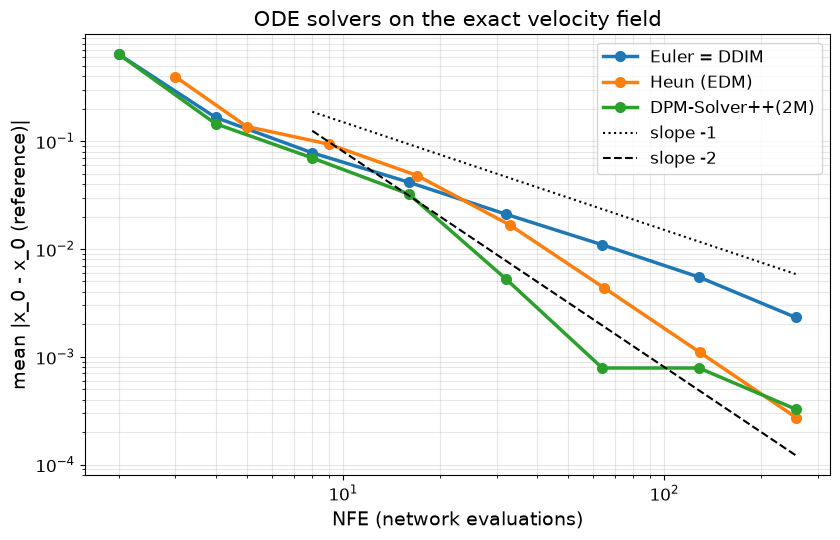

In [5]:
g = torch.Generator(device=DEVICE).manual_seed(0)
X1 = torch.randn(4000, 2, generator=g, device=DEVICE, dtype=torch.float64)
with Timer() as tm: X_REF = heun(exact_vel, X1, t_grid(4000))
print(f"reference (Heun, 4000 steps, float64): {tm.s:.1f} s; quality {({k: round(v, 3) for k, v in sample_quality(X_REF).items()})}")

CONV = {}
for name, solver, ns in [("Euler = DDIM", euler, [2, 4, 8, 16, 32, 64, 128, 256]), ("Heun (EDM)", heun, [2, 3, 5, 9, 17, 33, 65, 129]),
                         ("DPM-Solver++(2M)", dpmpp2m, [2, 4, 8, 16, 32, 64, 128, 256])]:
    key = {"Euler = DDIM": "euler", "Heun (EDM)": "heun", "DPM-Solver++(2M)": "dpmpp2m"}[name]
    CONV[name] = [(NFE[key](n), (solver(exact_vel, X1, t_grid(n)) - X_REF).norm(dim=1).mean().item()) for n in ns]
print(f"{'solver':18s} " + " ".join(f"{'NFE':>4s} {'error':>8s}" for _ in range(4)))
for name, rows in CONV.items():
    print(f"{name:18s} " + " ".join(f"{n:4d} {e:8.5f}" for n, e in rows[:4]) + "\n" + " " * 19 + " ".join(f"{n:4d} {e:8.5f}" for n, e in rows[4:]))
def order(rows, lo, hi):
    (n1, e1), (n2, e2) = [next(r for r in rows if r[0] >= v) for v in (lo, hi)]
    return f"NFE {n1:3d} -> {n2:3d}: {math.log(e1 / e2) / math.log(n2 / n1):5.2f}"
for name, rows in CONV.items():
    print(f"{name:18s} observed order  " + "   ".join(order(rows, lo, hi) for lo, hi in [(8, 32), (32, 128), (64, 256)]))

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for (name, rows), c in zip(CONV.items(), ["tab:blue", "tab:orange", "tab:green"]):
    ax.loglog(*zip(*rows), "o-", color=c, lw=2.5, ms=7, label=name)
n_ = np.array([8, 256.0]); ax.loglog(n_, 1.5 / n_, "k:", lw=1.5, label="slope -1"); ax.loglog(n_, 8 / n_ ** 2, "k--", lw=1.5, label="slope -2")
ax.set_xlabel("NFE (network evaluations)", fontsize=14); ax.set_ylabel("mean |x_0 - x_0 (reference)|", fontsize=14)
ax.set_title("ODE solvers on the exact velocity field", fontsize=15); ax.legend(fontsize=12); ax.grid(alpha=0.3, which="both"); ax.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

**Что видно.** Эталон (Heun, 4000 шагов) сам воспроизводит данные: $\log p = -0{,}138$, тяжёлых мод 0,795. Наблюдаемые порядки соответствуют теории только асимптотически. Euler даёт 0,94–1,12, то есть первый порядок: ошибка падает с 0,166 при 4 NFE до 0,0023 при 256. Heun выходит на второй порядок (2,00–2,01) лишь начиная с 33 NFE. На малых бюджетах его порядок 1,33, и при 9 NFE он хуже Эйлера с 8 NFE (0,094 против 0,078): крупный шаг не попадает в асимптотический режим (раздел 3.1). DPM-Solver++(2M) лучше всех в диапазоне 8–64 NFE (0,0053 при 32 NFE против 0,021 у Эйлера и 0,017 у Heun с 33). Потом его ошибка выходит на плато: 0,00079 и при 64, и при 128 NFE. Причина в равномерной сетке по $t$. Возле $t = 1$ шаги по $\lambda = \log\frac{1 - t}{t}$ стремятся к $\ln 2, \ln 1{,}5, \dots$ и не уменьшаются с ростом $n$ (раздел 3.4). DPM-Solver рассчитан на сетку, равномерную по $\lambda$. При 2 NFE DPM++ совпадает с Эйлером (0,639): первый шаг 2M — это DDIM, а последний просто возвращает $\hat x_0$.

### 9.3. DDIM — это шаг Эйлера, а расписание — это сетка времени

Проверим утверждение раздела 2.3 численно. Возьмём косинусное VP-расписание $\alpha_\tau = \cos(\pi\tau/2)$, $\sigma_\tau = \sin(\pi\tau/2)$ и сделаем обычный шаг DDIM в его координатах $y = \alpha_\tau x_0 + \sigma_\tau \epsilon$. Скорость при этом берём из той же модели линейного пути. Точка $y$ переводится в линейный путь делением на $\alpha_\tau + \sigma_\tau$, время — по формуле $t = \sigma_\tau/(\alpha_\tau + \sigma_\tau)$. Если DDIM действительно сводится к шагу Эйлера, то DDIM на равномерной по $\tau$ сетке должен в точности совпасть с Эйлером на сетке $t_i = \sigma_{\tau_i}/(\alpha_{\tau_i} + \sigma_{\tau_i})$. Тогда «DDIM с косинусным расписанием» и «Euler на rectified flow» различаются только сеткой времени.

In [6]:
@torch.no_grad()
def ddim_vp_cosine(vel, x1, n):
    taus = torch.linspace(1, 0, n + 1, dtype=torch.float64)
    al, si = torch.cos(taus * math.pi / 2), torch.sin(taus * math.pi / 2); si[-1] = 0.0; al[0] = 0.0
    y = x1.clone()                                                          # при tau = 1: y = eps = x_1
    for i in range(n):
        t = si[i] / (al[i] + si[i]); x = y / (al[i] + si[i])                # перевод в линейный путь
        u = vel(x, _tb(x, t.item())); x0, eps = x - t * u, x + (1 - t) * u
        y = al[i + 1] * x0 + si[i + 1] * eps                                # обычный шаг DDIM в координатах VP
    return y

for n in [4, 10, 25]:
    taus = torch.linspace(1, 0, n + 1, dtype=torch.float64)
    al, si = torch.cos(taus * math.pi / 2), torch.sin(taus * math.pi / 2); si[-1] = 0.0; al[0] = 0.0
    a = ddim_vp_cosine(exact_vel, X1, n); b = euler(exact_vel, X1, si / (al + si)); c = euler(exact_vel, X1, t_grid(n))
    print(f"n={n:2d}: max|DDIM(VP cosine) - Euler(mapped grid)| = {(a - b).abs().max().item():.1e}   "
          f"error vs reference: DDIM cosine grid {(a - X_REF).norm(dim=1).mean().item():.4f}, Euler uniform grid {(c - X_REF).norm(dim=1).mean().item():.4f}")

n= 4: max|DDIM(VP cosine) - Euler(mapped grid)| = 1.3e-15   error vs reference: DDIM cosine grid 0.1852, Euler uniform grid 0.1662
n=10: max|DDIM(VP cosine) - Euler(mapped grid)| = 1.4e-14   error vs reference: DDIM cosine grid 0.0678, Euler uniform grid 0.0646
n=25: max|DDIM(VP cosine) - Euler(mapped grid)| = 1.1e-13   error vs reference: DDIM cosine grid 0.0298, Euler uniform grid 0.0268


**Что видно.** DDIM с косинусным VP-расписанием и Эйлер на перенесённой сетке $\tau = \sigma/(\alpha + \sigma)$ совпадают до $10^{-15}$–$10^{-13}$: это одна и та же схема (раздел 2.3). Расписание влияет только на расположение узлов, и здесь косинусная сетка чуть хуже равномерной: 0,185 против 0,166 при 4 шагах, 0,030 против 0,027 при 25.

### 9.4. ODE, SDE и predictor-corrector

Стохастические сэмплеры нельзя сравнивать с эталонным решением ОДУ точка в точку, поэтому сравниваем распределения: средний $\log p_{\text{data}}$, долю точек в тяжёлых модах (у данных 0,8) и долю точек вне мод. На точном поле единственный источник ошибки — дискретизация. 20 000 стартовых точек, одинаковые бюджеты NFE.

In [7]:
g = torch.Generator(device=DEVICE).manual_seed(1)
X1b = torch.randn(20000, 2, generator=g, device=DEVICE, dtype=torch.float64)
print(f"{'sampler':26s} {'NFE':>4s} {'mean log p':>11s} {'heavy':>7s} {'off-mode':>9s}")
SDE_TAB = {}
for budget in [5, 11, 21, 51]:
    runs = [("ODE Euler (DDIM eta=0)", lambda: euler(exact_vel, X1b, t_grid(budget)), budget),
            ("ODE DPM-Solver++(2M)", lambda: dpmpp2m(exact_vel, X1b, t_grid(budget)), budget),
            ("SDE (DDIM eta=1)", lambda: ddim_eta(exact_vel, X1b, t_grid(budget), 1.0, torch.Generator(device=DEVICE).manual_seed(2)), budget),
            ("PC, snr = 0.02", lambda: pc(exact_vel, X1b, t_grid((budget + 1) // 2), 0.02, torch.Generator(device=DEVICE).manual_seed(2)), budget),
            ("PC, snr = 0.1", lambda: pc(exact_vel, X1b, t_grid((budget + 1) // 2), 0.1, torch.Generator(device=DEVICE).manual_seed(2)), budget)]
    for name, fn, nfe in runs:
        q = sample_quality(fn()); SDE_TAB[(name, nfe)] = q
        print(f"{name:26s} {nfe:4d} {q['logp']:11.3f} {q['heavy']:7.3f} {q['off']:9.3f}")
q = sample_quality(ddim_eta(exact_vel, X1b, t_grid(1000), 1.0, torch.Generator(device=DEVICE).manual_seed(2)))
print(f"{'SDE (DDIM eta=1)':26s} {1000:4d} {q['logp']:11.3f} {q['heavy']:7.3f} {q['off']:9.3f}")
q = sample_quality(sample_data(20000, torch.Generator(device=DEVICE).manual_seed(9)))
print(f"{'data':26s} {'-':>4s} {q['logp']:11.3f} {q['heavy']:7.3f} {q['off']:9.3f}")

sampler                     NFE  mean log p   heavy  off-mode
ODE Euler (DDIM eta=0)        5      -1.226   0.740     0.090
ODE DPM-Solver++(2M)          5      -0.693   0.760     0.067


SDE (DDIM eta=1)              5      -1.298   0.742     0.092
PC, snr = 0.02                5      -7.370   0.827     0.394
PC, snr = 0.1                 5      -6.255   0.831     0.348


ODE Euler (DDIM eta=0)       11      -0.012   0.769     0.009
ODE DPM-Solver++(2M)         11       0.390   0.797     0.003


SDE (DDIM eta=1)             11       0.188   0.781     0.007
PC, snr = 0.02               11      -0.395   0.762     0.043


PC, snr = 0.1                11      -1.022   0.750     0.058


ODE Euler (DDIM eta=0)       21      -0.001   0.785     0.002


... (6 outputs left out)

SDE (DDIM eta=1)             51       0.143   0.799     0.000


PC, snr = 0.02               51       0.142   0.793     0.002


PC, snr = 0.1                51      -0.704   0.762     0.019


SDE (DDIM eta=1)           1000      -0.101   0.802     0.000
data                          -      -0.130   0.800     0.001


**Что видно.** При 5 NFE плохи все сэмплеры, но DPM++ лучше остальных: $\log p = -0{,}69$ и 6,7 % точек вне мод против 9 % у Эйлера и SDE. Predictor-corrector при том же бюджете делает всего 3 шага предиктора и проваливается: $\log p$ от $-6$ до $-7$, вне мод 35–39 %. При 11 NFE Эйлер ближе всех к данным ($-0{,}012$ против $-0{,}13$), а DPM++ и SDE дают $\log p$ выше, чем у данных (0,39 и 0,19): точки слишком стянуты к центрам мод. Отклонение от данных в обе стороны — ошибка дискретизации. PC при 11 NFE всё ещё хуже ODE-решателей ($-0{,}40$ и $-1{,}02$, вне мод 4–6 %), а с $\mathrm{snr} = 0{,}1$ он хуже при любом бюджете. К 51 NFE ODE-решатели почти сходятся (Эйлер $-0{,}053$, DPM++ $-0{,}117$), а SDE и PC всё ещё смещены (0,14). Даже при 1000 шагах SDE даёт $-0{,}10$. Вывод раздела 2.4 подтверждается: при равном NFE детерминированные решатели не хуже стохастических, а корректор Ланжевена при фиксированном бюджете вызовов не окупается.

## 10. Двумерный пример: flow matching и reflow

### 10.1. Обучение по условным путям

Сеть-скорость обучается функцией потерь conditional flow matching (раздел 4.3): берём пару $(x_0, \epsilon)$ с независимыми $x_0 \sim p_{\text{data}}$ и $\epsilon \sim \mathcal{N}(0, I)$, точку $x_t = (1-t)x_0 + t\epsilon$ и регрессируем $u_\theta(x_t, t)$ на $\epsilon - x_0$. Сеть ни разу не видит маргинальную скорость $u_t(x)$, но минимум функции потерь достигается именно на ней. Проверим это сравнением с точным полем из раздела 9. Время подаётся в сеть как $1000\,t$ через синусоидальное кодирование, как номер шага в лекции 12.

In [8]:
def timestep_embedding(t, dim, max_period=10000):
    """Синусоидальное кодирование времени; t — номер шага (у нас 1000 * t)."""
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, device=t.device) / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([a.cos(), a.sin()], -1)

class MLP2D(nn.Module):
    def __init__(self, h=256, temb=64):
        super().__init__(); self.temb = temb
        self.net = nn.Sequential(nn.Linear(2 + temb, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(),
                                 nn.Linear(h, h), nn.SiLU(), nn.Linear(h, 2))
    def forward(self, x, t): return self.net(torch.cat([x.float(), timestep_embedding(1000 * t, self.temb)], -1)).to(x.dtype)

def train_fm_2d(steps, pairs=None, init=None, bs=1024, lr=2e-3, seed=0):
    """pairs=None: независимая пара (x0, eps); иначе пары (eps, x0) из предыдущего потока (reflow)."""
    seed_all(seed); m = (copy.deepcopy(init) if init is not None else MLP2D().to(DEVICE)).requires_grad_(True)
    opt = torch.optim.Adam(m.parameters(), lr); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    m.train()
    for i in range(steps):
        if pairs is None: x0, eps = sample_data(bs), torch.randn(bs, 2, device=DEVICE)
        else:
            j = torch.randint(0, len(pairs[0]), (bs,), device=DEVICE); eps, x0 = pairs[0][j], pairs[1][j]
        t = torch.rand(bs, device=DEVICE)
        loss = F.mse_loss(m((1 - t[:, None]) * x0 + t[:, None] * eps, t), eps - x0)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return m.eval().requires_grad_(False)

with Timer() as tm: RF1 = train_fm_2d(S["steps_2d"])
vel_rf1 = lambda x, t: RF1(x, t)
print(f"1-rectified flow (independent coupling): {S['steps_2d']} steps, {tm.s:.0f} s")
g = torch.Generator(device=DEVICE).manual_seed(3)
for tv in [0.05, 0.3, 0.6, 0.9]:
    x0 = sample_data(5000, g); xt = (1 - tv) * x0 + tv * torch.randn(5000, 2, generator=g, device=DEVICE)
    ue, ul = exact_vel(xt.double(), tv).float(), vel_rf1(xt, _tb(xt, tv))
    print(f"t={tv:.2f}: |exact u| = {ue.norm(dim=1).mean().item():.3f}, mean |learned - exact| = {(ul - ue).norm(dim=1).mean().item():.3f}, "
          f"cosine = {F.cosine_similarity(ul, ue, dim=1).mean().item():.3f}")

1-rectified flow (independent coupling): 3000 steps, 17 s
t=0.05: |exact u| = 1.549, mean |learned - exact| = 0.054, cosine = 0.999
t=0.30: |exact u| = 1.439, mean |learned - exact| = 0.072, cosine = 0.989
t=0.60: |exact u| = 0.255, mean |learned - exact| = 0.040, cosine = 0.936
t=0.90: |exact u| = 1.102, mean |learned - exact| = 0.027, cosine = 1.000


**Что видно.** Сеть, обученная только на условных скоростях $\epsilon - x_0$, за 17 с выучила маргинальное поле: косинус с точным полем 0,999 при $t = 0{,}05$ и 1,000 при $t = 0{,}9$. Это численная проверка утверждения раздела 4.3. Хуже всего согласие при $t = 0{,}6$ (косинус 0,936). Именно там точное поле почти нулевое ($|u| = 0{,}255$ против 1,1–1,5 на краях): прямые с разными направлениями пересекаются, и их скорости в среднем гасят друг друга (раздел 5.1).

### 10.2. Reflow

Reflow ([Liu et al., 2023](https://arxiv.org/abs/2209.03003)) берёт обученный поток и строит новую пару: $\epsilon$ и точку $\hat x_0 = \mathrm{ODE}(\epsilon)$, в которую поток его переводит. На таких парах (а не на независимых) снова обучается flow matching, начиная с весов предыдущей модели. Пары берутся из 20 000 решений ОДУ (Heun, 32 шага).

Метрики:

- прямота $S = \int_0^1 \mathbb{E}\,\|u(x_t, t) - (x_1 - x_0)\|^2\,dt$ вдоль траекторий самой ОДУ: 0 у прямых траекторий (раздел 5.2);
- транспортная стоимость $\mathbb{E}\|x_1 - x_0\|^2$ между стартом и финишем: по теореме Liu et al. reflow её не увеличивает;
- качество выборки при 1, 2, 4 и 8 шагах Эйлера.

In [9]:
def make_pairs(vel, n, seed=0, steps=32):
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    eps = torch.randn(n, 2, generator=g, device=DEVICE)
    return eps, heun(vel, eps, t_grid(steps).to(eps.dtype))

@torch.no_grad()
def straightness(vel, n=4000, steps=100, seed=7):
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    x1 = torch.randn(n, 2, generator=g, device=DEVICE); ts = t_grid(steps).to(x1.dtype)
    x0, path = euler(vel, x1, ts, traj=True)
    disp = x1 - x0                                                           # прямая от x_0 до x_1
    us = torch.stack([vel(path[i], _tb(x1, ts[i])) for i in range(steps)])
    return ((us - disp) ** 2).sum(-1).mean().item(), (disp ** 2).sum(-1).mean().item()

with Timer() as tm:
    PAIRS_2D = make_pairs(vel_rf1, 20000)
    RF2 = train_fm_2d(S["steps_reflow_2d"], pairs=PAIRS_2D, init=RF1, lr=1e-3, seed=1)
vel_rf2 = lambda x, t: RF2(x, t)
print(f"2-rectified flow: pairs + {S['steps_reflow_2d']} steps, {tm.s:.0f} s\n")

X1q = torch.randn(20000, 2, generator=torch.Generator(device=DEVICE).manual_seed(11), device=DEVICE)
print(f"{'flow':26s} {'straightness S':>15s} {'E|x1 - x0|^2':>13s}   " + "   ".join(f"Euler {n}: logp / off" for n in [1, 2, 4, 8]))
RF2D = {}
for name, v in [("exact field (1-RF ideal)", lambda x, t: exact_vel(x.double(), t).float()), ("1-RF, learned", vel_rf1), ("2-RF (after reflow)", vel_rf2)]:
    Sv, cost = straightness(v)
    qs = [sample_quality(euler(v, X1q, t_grid(n).float())) for n in [1, 2, 4, 8]]; RF2D[name] = (Sv, cost, qs)
    print(f"{name:26s} {Sv:15.3f} {cost:13.3f}   " + "   ".join(f"{q['logp']:7.2f} / {q['off']:.3f}" for q in qs))
x0i = sample_data(20000, torch.Generator(device=DEVICE).manual_seed(9))
print(f"{'independent pairs':26s} {'':15s} {((X1q - x0i) ** 2).sum(1).mean().item():13.3f}   (cost of the coupling used to train 1-RF)")
q = sample_quality(x0i)
print(f"{'data':26s} {'':15s} {'':13s}   logp {q['logp']:.2f}, off {q['off']:.3f}")

2-rectified flow: pairs + 1500 steps, 12 s

flow                        straightness S  E|x1 - x0|^2   Euler 1: logp / off   Euler 2: logp / off   Euler 4: logp / off   Euler 8: logp / off


exact field (1-RF ideal)             1.125         0.501    -50.00 / 1.000    -21.67 / 0.830     -2.66 / 0.168     -0.13 / 0.023


1-RF, learned                        1.104         0.494    -50.00 / 1.000    -21.46 / 0.809     -3.07 / 0.185     -0.91 / 0.072


2-RF (after reflow)                  0.003         0.486     -1.95 / 0.126     -1.40 / 0.086     -1.19 / 0.077     -1.04 / 0.069
independent pairs                                  4.257   (cost of the coupling used to train 1-RF)
data                                                       logp -0.13, off 0.001


**Что видно.** Траектории 1-RF сильно искривлены: $S = 1{,}125$ для точного поля и 1,104 для выученного. После одного reflow $S = 0{,}003$, то есть траектории практически прямые. Транспортная стоимость не выросла (0,494 → 0,486), как и обещает теорема Liu et al. Она в 9 раз меньше, чем у независимых пар, на которых обучался 1-RF (4,26). Один шаг Эйлера у 1-RF бесполезен: все точки попадают в центр, между модами ($\log p$ упирается в нижнюю границу $-50$, вне мод 100 %). У 2-RF один шаг даёт $\log p = -1{,}95$ и 12,6 % вне мод. Но к 8 шагам 2-RF не догоняет 1-RF ($-1{,}04$ против $-0{,}91$), а точное поле при 8 шагах уже даёт $-0{,}13$. Ошибка 2-RF теперь определяется не кривизной, а неточностью обучения на парах (1500 шагов). Её reflow не устраняет, а добавляет к ошибке 1-RF, которым пары построены.

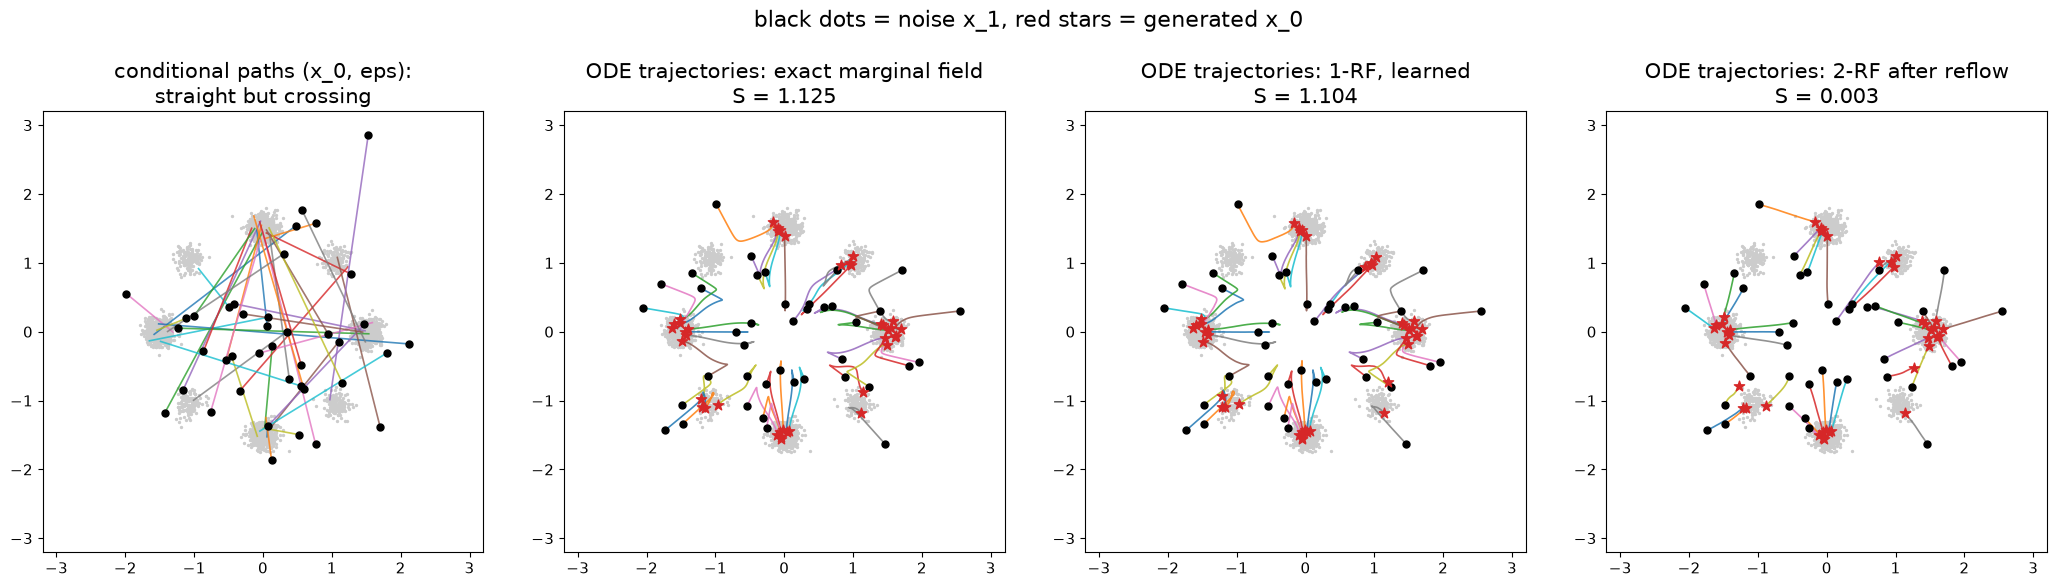

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(21, 5.6))
g = torch.Generator(device=DEVICE).manual_seed(5)
x0s, e0s = sample_data(40, g), torch.randn(40, 2, generator=g, device=DEVICE)
bg = sample_data(3000, torch.Generator(device=DEVICE).manual_seed(4)).cpu()
ax[0].scatter(bg[:, 0], bg[:, 1], s=2, c="0.8")
for a_, b_ in zip(x0s.cpu(), e0s.cpu()): ax[0].plot([a_[0], b_[0]], [a_[1], b_[1]], lw=1.2, alpha=0.8)
ax[0].scatter(e0s[:, 0].cpu(), e0s[:, 1].cpu(), s=25, c="k", zorder=3); ax[0].set_title("conditional paths (x_0, eps):\nstraight but crossing", fontsize=15)
xs = torch.randn(40, 2, generator=torch.Generator(device=DEVICE).manual_seed(6), device=DEVICE)
for a, (name, v) in zip(ax[1:], [("exact marginal field", lambda x, t: exact_vel(x.double(), t).float()), ("1-RF, learned", vel_rf1), ("2-RF after reflow", vel_rf2)]):
    _, P = euler(v, xs, t_grid(100).float(), traj=True); P = P.cpu()
    a.scatter(bg[:, 0], bg[:, 1], s=2, c="0.8")
    for j in range(P.shape[1]): a.plot(P[:, j, 0], P[:, j, 1], lw=1.2, alpha=0.85)
    a.scatter(P[0, :, 0], P[0, :, 1], s=25, c="k", zorder=3); a.scatter(P[-1, :, 0], P[-1, :, 1], s=60, marker="*", c="tab:red", zorder=3)
    a.set_title(f"ODE trajectories: {name}\nS = {straightness(v)[0]:.3f}", fontsize=15)
for a in ax: a.set_aspect("equal"); a.set_xlim(-3.2, 3.2); a.set_ylim(-3.2, 3.2); a.tick_params(labelsize=11)
plt.suptitle("black dots = noise x_1, red stars = generated x_0", fontsize=16, y=0.995); plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

**Что видно.** Слева — условные пути: прямые, но они пересекаются, и одной точке в середине соответствуют разные направления. В середине — траектории точного и выученного маргинального поля 1-RF. Они не пересекаются, но сначала идут к центру, а потом поворачивают к модам. Картинки почти неотличимы, что подтверждает косинусы из предыдущей ячейки. Справа — 2-RF: от каждой чёрной точки к звезде идёт почти прямой отрезок. Платой за это стала точность: несколько звёзд 2-RF оказались между модами.

## 11. MNIST: базовая модель flow matching

### 11.1. Сеть и обучение

Сеть — та же маленькая U-Net, что в лекции 12 (AdaGN по эмбеддингу времени и класса, self-attention на разрешении 7×7, нулевая инициализация выходного слоя). Отличие одно: на вход подаётся непрерывное $t \in [0, 1]$, а предсказывается скорость линейного пути $u = \epsilon - x_0$, а не $v$ косинусного расписания. Модель условна по классу; classifier-free guidance в этой лекции не используется, чтобы NFE был равен числу шагов (с CFG каждый шаг стоит два вызова сети, раздел 6.5). Для генерации берутся EMA-веса.

Функция `train_loop` общая для всех моделей лекции: базовой, reflow, progressive и consistency distillation. Каждая из них задаёт только свою функцию потерь `loss_fn(model, x0, y)`.

In [11]:
class ResBlock(nn.Module):
    def __init__(self, cin, cout, edim, drop=0.0):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(edim, 2 * cout)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv2d(cout, cout, 3, padding=1)
        self.drop = nn.Dropout(drop); self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x)))
        g, b = self.emb(F.silu(e))[:, :, None, None].chunk(2, 1)
        h = self.n2(h) * (1 + g) + b                                     # AdaGN: условие масштабирует и сдвигает признаки
        return self.skip(x) + self.c2(self.drop(F.silu(h)))

class Attn(nn.Module):
    def __init__(self, c, heads=4):
        super().__init__(); self.n, self.h = nn.GroupNorm(8, c), heads
        self.qkv, self.out = nn.Conv2d(c, 3 * c, 1), nn.Conv2d(c, c, 1)
    def forward(self, x, e=None):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.n(x)).reshape(B, 3, self.h, C // self.h, H * W).transpose(-1, -2).unbind(1)
        o = F.scaled_dot_product_attention(q, k, v).transpose(-1, -2).reshape(B, C, H, W)
        return x + self.out(o)

class UNet(nn.Module):
    def __init__(self, ch=32, mult=(1, 2, 2), n_res=2, attn_res=(7,), n_cls=10, drop=0.0):
        super().__init__(); edim = 4 * ch; self.ch = ch
        self.t_mlp = nn.Sequential(nn.Linear(ch, edim), nn.SiLU(), nn.Linear(edim, edim))
        self.cls = nn.Embedding(n_cls, edim)
        self.inp = nn.Conv2d(1, ch, 3, padding=1)
        self.down, chans, c, res = nn.ModuleList(), [ch], ch, 28
        for i, m in enumerate(mult):
            for _ in range(n_res):
                blk = nn.ModuleList([ResBlock(c, ch * m, edim, drop)]); c = ch * m
                if res in attn_res: blk.append(Attn(c))
                self.down.append(blk); chans.append(c)
            if i < len(mult) - 1:
                self.down.append(nn.ModuleList([nn.Conv2d(c, c, 3, stride=2, padding=1)])); chans.append(c); res //= 2
        self.mid = nn.ModuleList([ResBlock(c, c, edim, drop), Attn(c), ResBlock(c, c, edim, drop)])
        self.up = nn.ModuleList()
        for i, m in reversed(list(enumerate(mult))):
            for _ in range(n_res + 1):
                blk = nn.ModuleList([ResBlock(c + chans.pop(), ch * m, edim, drop)]); c = ch * m
                if res in attn_res: blk.append(Attn(c))
                self.up.append(blk)
            if i > 0: self.up.append(nn.ModuleList([nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(c, c, 3, padding=1)])); res *= 2
        self.out = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv2d(c, 1, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight); nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, t, y):
        e = self.t_mlp(timestep_embedding(1000 * t, self.ch)) + self.cls(y)        # t в [0, 1]
        h = self.inp(x); hs = [h]
        for blk in self.down:
            if isinstance(blk[0], ResBlock):
                h = blk[0](h, e)
                if len(blk) > 1: h = blk[1](h)
            else: h = blk[0](h)
            hs.append(h)
        h = self.mid[2](self.mid[1](self.mid[0](h, e)), e)
        for blk in self.up:
            if isinstance(blk[0], ResBlock):
                h = blk[0](torch.cat([h, hs.pop()], 1), e)
                if len(blk) > 1: h = blk[1](h)
            else: h = blk[1](blk[0](h))
        return self.out(h)

n_params = lambda m: sum(p.numel() for p in m.parameters())
UNET_KW = dict(ch=S["ch"], mult=S["mult"], n_res=S["n_res"])

class EMA:
    def __init__(self, model, decay=0.999):
        self.m = copy.deepcopy(model).eval().requires_grad_(False); self.decay, self.n = decay, 0
    @torch.no_grad()
    def update(self, model):
        self.n += 1; d = min(self.decay, (1 + self.n) / (10 + self.n))       # короткий «разогрев» в начале
        for pe, p in zip(self.m.parameters(), model.parameters()): pe.lerp_(p, 1 - d)

def train_loop(model, steps, loss_fn, lr=1e-3, warm=200, seed=0, ema_decay=0.999, data=None):
    """Общий цикл: AdamW, прогрев lr, клиппинг градиента, EMA. data: итератор батчей (x0 в [-1, 1], y)."""
    seed_all(seed); model.train().requires_grad_(True)
    opt = torch.optim.AdamW(model.parameters(), lr, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1.0, (i + 1) / warm))
    ema, hist, run = EMA(model, ema_decay), [], []
    data = data or ((to_m1(x), y) for x, y in batches(Xtr, Ytr, S["bs"], steps, seed=seed + 10))
    log_every = max(1, min(100, steps // 10))
    for step, (x0, y) in enumerate(data):
        loss = loss_fn(model, x0, y)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        ema.update(model); run.append(loss.item())
        if (step + 1) % log_every == 0: hist.append((step + 1, float(np.mean(run)))); run = []
        if step + 1 >= steps: break
    model.eval().requires_grad_(False)
    return ema.m, hist

def fm_loss(model, x0, y):
    t = torch.rand(len(x0), device=DEVICE); eps = torch.randn_like(x0); tt = t.view(-1, 1, 1, 1)
    return F.mse_loss(model((1 - tt) * x0 + tt * eps, t, y), eps - x0)

seed_all(0); net = UNet(**UNET_KW).to(DEVICE)
print(f"U-Net: {n_params(net) / 1e6:.2f}M parameters")
with Timer() as tm: BASE, H_BASE = train_loop(net, S["steps_base"], fm_loss)
TRAIN_COST = {"base flow matching": tm.s}
print(f"base model: {S['steps_base']} steps in {tm.s / 60:.1f} min ({tm.s / S['steps_base']:.3f} s/step); "
      f"loss first {H_BASE[0][0]} steps {H_BASE[0][1]:.4f}, last 100 steps {H_BASE[-1][1]:.4f}")

U-Net: 0.72M parameters


base model: 2000 steps in 10.1 min (0.302 s/step); loss first 100 steps 1.4006, last 100 steps 0.1741


**Что видно.** U-Net с 0,72 млн параметров обучилась за 2000 шагов и 10,1 мин (0,30 с на шаг). Потеря упала с 1,40 до 0,174, но не до нуля. Остаток — неустранимая условная дисперсия $\mathbb E\|\epsilon - x_0 - u(x_t)\|^2$ из раздела 4.3: по $x_t$ нельзя точно восстановить пару, из которой он получен.

### 11.2. Одна сеть, две параметризации

Скорость линейного пути однозначно задаёт и предсказание данных, и предсказание шума: $\hat x_0 = x_t - t\,\hat u$, $\hat\epsilon = x_t + (1 - t)\,\hat u$ (раздел 4.4). Поэтому та же сеть — это обычная диффузионная модель, и к ней применимы DDIM и DPM-Solver. Ниже показаны ошибки на тесте по уровням шума в трёх пространствах. Видно, где модели трудно: в пространстве $\hat x_0$ ошибка максимальна у шума, в пространстве $\hat\epsilon$ — у данных.

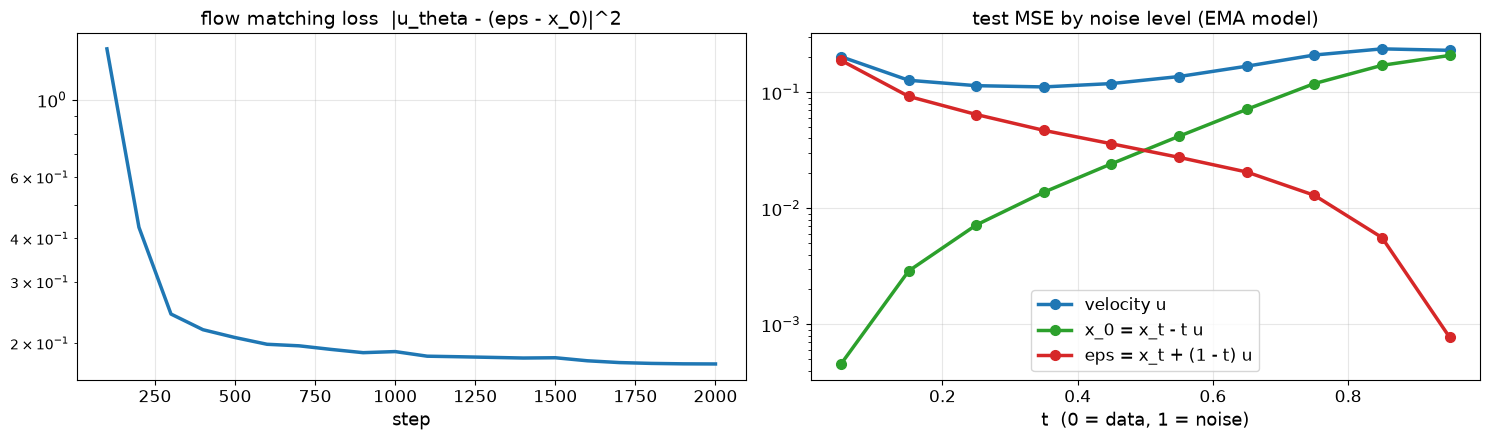

t bucket    0.05   0.15   0.25   0.35   0.45   0.55   0.65   0.75   0.85   0.95
MSE u      0.203  0.127  0.114  0.111  0.119  0.137  0.168  0.210  0.237  0.230
MSE x0     0.000  0.003  0.007  0.014  0.024  0.042  0.071  0.119  0.171  0.208
MSE eps    0.188  0.092  0.064  0.047  0.036  0.028  0.021  0.013  0.006  0.001


In [12]:
@torch.no_grad()
def errors_by_t(model, n=1000, buckets=10, seed=5):
    g = torch.Generator(device=DEVICE).manual_seed(seed); rows = []
    idx = torch.randperm(len(Xte), generator=torch.Generator().manual_seed(seed))[:n]
    x0, y = to_m1(Xte[idx]).to(DEVICE), Yte[idx].to(DEVICE)
    for b in range(buckets):
        t = (b + torch.rand(n, generator=g, device=DEVICE)) / buckets; tt = t.view(-1, 1, 1, 1)
        eps = torch.randn(x0.shape, generator=g, device=DEVICE); xt = (1 - tt) * x0 + tt * eps
        u = model(xt, t, y)
        rows.append([F.mse_loss(u, eps - x0).item(), F.mse_loss(xt - tt * u, x0).item(), F.mse_loss(xt + (1 - tt) * u, eps).item()])
    return np.array(rows)

E_BASE = errors_by_t(BASE)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(*zip(*H_BASE), lw=2.5); ax[0].set_yscale("log"); ax[0].set_xlabel("step", fontsize=13)
ax[0].set_title("flow matching loss  |u_theta - (eps - x_0)|^2", fontsize=14)
mid = (np.arange(10) + 0.5) / 10
for j, (lab, c) in enumerate([("velocity u", "tab:blue"), ("x_0 = x_t - t u", "tab:green"), ("eps = x_t + (1 - t) u", "tab:red")]):
    ax[1].plot(mid, E_BASE[:, j], "o-", color=c, lw=2.5, ms=7, label=lab)
ax[1].set_yscale("log"); ax[1].set_xlabel("t  (0 = data, 1 = noise)", fontsize=13); ax[1].set_title("test MSE by noise level (EMA model)", fontsize=14)
for a in ax: a.legend(fontsize=12) if a is ax[1] else None; a.grid(alpha=0.3); a.tick_params(labelsize=12)
plt.tight_layout(); plt.show()
print("t bucket   " + "  ".join(f"{m:5.2f}" for m in mid))
for j, lab in enumerate(["MSE u", "MSE x0", "MSE eps"]): print(f"{lab:9s}  " + "  ".join(f"{v:5.3f}" for v in E_BASE[:, j]))

**Что видно.** Справа ошибка скорости минимальна при $t \approx 0{,}25$–$0{,}45$ и выше всего у шума (0,237 при $t = 0{,}85$). Ошибки $\hat x_0$ и $\hat\epsilon$ — это та же ошибка, умноженная на $t^2$ и $(1 - t)^2$. Поэтому в пространстве $\hat x_0$ модель ошибается в основном у шума (0,208), а в пространстве $\hat\epsilon$ — у данных (0,188). Возле данных $\hat\epsilon$ определяется лучше, чем можно было ожидать (0,188, а не около 1): у MNIST большая часть изображения — постоянный фон, и шум на фоне восстанавливается точно.

## 12. MNIST: сэмплеры при малом NFE

### 12.1. Протокол сравнения

Все модели оцениваются одинаково:

- генерируется `n_eval` изображений, поровну каждого класса, из фиксированного шума (одни и те же $x_1$ для всех методов);
- считаются FD, acc, div и conf классификатора-оценщика (раздел 8.4);
- NFE — число вызовов сети на одно изображение;
- время — полное время генерации всей выборки батчами по 250 на этом устройстве.

Результаты накапливаются в словаре `RESULTS`, из которого в разделе 16 строится Парето-фронт. Сетка времени равномерная по $t$, если не сказано иное.

In [13]:
RESULTS = {}
GEN_BS = 250
X1_EVAL = torch.randn(S["n_eval"], 1, 28, 28, generator=torch.Generator().manual_seed(123))

@torch.no_grad()
def generate(sample_fn, n=None, seed=0):
    """sample_fn(vel, x1, y, gen) -> x0 в [-1, 1]; vel(x, t) уже знает классы своего батча."""
    n = n or S["n_eval"]; out = []
    for i in range(0, n, GEN_BS):
        x1, y = X1_EVAL[i:i + GEN_BS].to(DEVICE), Y_EVAL[i:i + GEN_BS].to(DEVICE)
        gen = torch.Generator(device=DEVICE).manual_seed(seed + i)
        out.append(sample_fn(x1, y, gen).cpu())
    return to_01(torch.cat(out))

def run(name, method, nfe, sample_fn, verbose=True):
    with Timer() as tm: imgs = generate(sample_fn)
    r = evaluate(imgs, Y_EVAL); r.update(NFE=nfe, time=tm.s, method=method); RESULTS[name] = r
    if verbose: print(f"{name:37s} NFE={nfe:4d}  time={tm.s:6.1f} s  FD={r['FD']:6.2f}  acc={r['acc']:.3f}  div={r['div']:.3f}  conf={r['conf']:.3f}")
    return imgs

def solver_fn(model, solver, n, shift=1.0, **kw):
    """Обёртка: решатель из раздела 9 + модель, условная по классу."""
    def f(x1, y, gen):
        vel = lambda x, t: model(x, t, y)
        extra = dict(gen=gen) if solver in (ddim_eta, pc) else {}
        return solver(vel, x1, t_grid(n, shift).float(), **extra, **kw)
    return f

IMGS = {}
for n in [1, 2, 4, 8, 16, 32]:
    IMGS[("euler", n)] = run(f"base, Euler (DDIM), {n} steps", "base + Euler", n, solver_fn(BASE, euler, n))
for n in [2, 3, 5, 9]:
    IMGS[("heun", n)] = run(f"base, Heun, {n} steps", "base + Heun", 2 * n - 1, solver_fn(BASE, heun, n))
for n in [2, 4, 8, 16]:
    IMGS[("dpm", n)] = run(f"base, DPM-Solver++(2M), {n} steps", "base + DPM-Solver++", n, solver_fn(BASE, dpmpp2m, n))
_ = run("base, Heun, 33 steps (reference)", "base + Heun", 65, solver_fn(BASE, heun, 33))

base, Euler (DDIM), 1 steps           NFE=   1  time=   0.9 s  FD=174.66  acc=1.000  div=0.181  conf=0.912


base, Euler (DDIM), 2 steps           NFE=   2  time=   1.7 s  FD= 36.92  acc=0.990  div=0.585  conf=0.948


base, Euler (DDIM), 4 steps           NFE=   4  time=   3.2 s  FD=  9.78  acc=0.968  div=0.771  conf=0.933


base, Euler (DDIM), 8 steps           NFE=   8  time=   6.5 s  FD=  4.06  acc=0.958  div=0.845  conf=0.923


base, Euler (DDIM), 16 steps          NFE=  16  time=  12.8 s  FD=  2.75  acc=0.952  div=0.884  conf=0.916


base, Euler (DDIM), 32 steps          NFE=  32  time=  25.7 s  FD=  2.22  acc=0.948  div=0.900  conf=0.914


... (5 outputs left out)

base, DPM-Solver++(2M), 4 steps       NFE=   4  time=   3.3 s  FD=  6.55  acc=0.966  div=0.803  conf=0.930


base, DPM-Solver++(2M), 8 steps       NFE=   8  time=   6.5 s  FD=  2.48  acc=0.954  div=0.892  conf=0.915


base, DPM-Solver++(2M), 16 steps      NFE=  16  time=  13.0 s  FD=  2.24  acc=0.942  div=0.917  conf=0.909


base, Heun, 33 steps (reference)      NFE=  65  time=  52.8 s  FD=  2.03  acc=0.938  div=0.925  conf=0.909


**Что видно.** Один шаг Эйлера у базовой модели бесполезен: FD 174,7. Это размытые «средние цифры». Классификатор узнаёт их безошибочно (acc 1,000), но разнообразие 0,18, так что точность класса сама по себе о качестве не говорит. С ростом NFE Эйлер ведёт себя как метод первого порядка: FD 36,9 / 9,78 / 4,06 / 2,75 / 2,22 при 2 / 4 / 8 / 16 / 32. DPM-Solver++(2M) при 2 NFE совпадает с Эйлером (36,92), как и в 2D. Начиная с 4 NFE он заметно лучше: 6,55 против 9,78 при 4, 2,48 против 4,06 при 8, 2,24 против 2,75 при 16. Heun на 2 шагах (3 NFE) даёт 12,3, но уже на 3 шагах (5 NFE) — 3,78, лучше Эйлера с 8 NFE. При 9 NFE Heun достигает 1,98, что не хуже эталона Heun с 65 NFE (2,03). При $n = 500$ такие разницы меньше шума метрики, и выше примерно 9 NFE базовая модель упирается в собственное качество, а не в решатель. Один вызов сети на 500 изображений стоит около 0,8 с.

### 12.2. Стохастические сэмплеры и сетка времени

Две проверки. Первая — SDE (DDIM с $\eta = 1$) и predictor-corrector с тем же $\mathrm{snr} = 0{,}02$, который лучше всего работал в 2D (раздел 9.4). Вторая — та же схема Эйлера с 8 шагами на сдвинутой сетке: $t' = st/(1 + (s-1)t)$. При $s > 1$ шаги сгущаются у шума, как в Stable Diffusion 3 ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)); при $s < 1$ — у данных.

In [14]:
for n in [8, 16]:
    _ = run(f"base, SDE (DDIM eta=1), {n} steps", "base + SDE / PC", n, solver_fn(BASE, ddim_eta, n, eta=1.0))
_ = run("base, PC (eta=1 + Langevin), 8 steps", "base + SDE / PC", 15, solver_fn(BASE, pc, 8, snr=0.02))
for sh in [0.5, 2.0]:
    _ = run(f"base, Euler, 8 steps, shift {sh}", "base + Euler", 8, solver_fn(BASE, euler, 8, shift=sh))

base, SDE (DDIM eta=1), 8 steps       NFE=   8  time=   6.3 s  FD=  4.51  acc=0.966  div=0.800  conf=0.937


base, SDE (DDIM eta=1), 16 steps      NFE=  16  time=  12.7 s  FD=  3.13  acc=0.948  div=0.841  conf=0.928


base, PC (eta=1 + Langevin), 8 steps  NFE=  15  time=  12.4 s  FD=  4.57  acc=0.966  div=0.777  conf=0.947


base, Euler, 8 steps, shift 0.5       NFE=   8  time=   6.6 s  FD=  6.53  acc=0.960  div=0.815  conf=0.925


base, Euler, 8 steps, shift 2.0       NFE=   8  time=   6.5 s  FD=  3.43  acc=0.964  div=0.849  conf=0.925


**Что видно.** Стохастические сэмплеры при том же NFE хуже детерминированных. У SDE ($\eta = 1$) FD 4,51 при 8 шагах и 3,13 при 16, тогда как у Эйлера 4,06 и 2,75, а у DPM++ 2,48 и 2,24. Predictor-corrector тратит 15 NFE и даёт 4,57, то есть хуже, чем Эйлер за 8 NFE. Это повторяет вывод раздела 9.4. Сетка времени важна не меньше решателя. Сдвиг $s = 2$, сгущающий шаги у шума, улучшает Эйлера с 8 шагами с 4,06 до 3,43. Сдвиг $s = 0{,}5$ к данным ухудшает до 6,53. У этой модели самые трудные шаги — при большом шуме, где выбирается общая форма цифры.

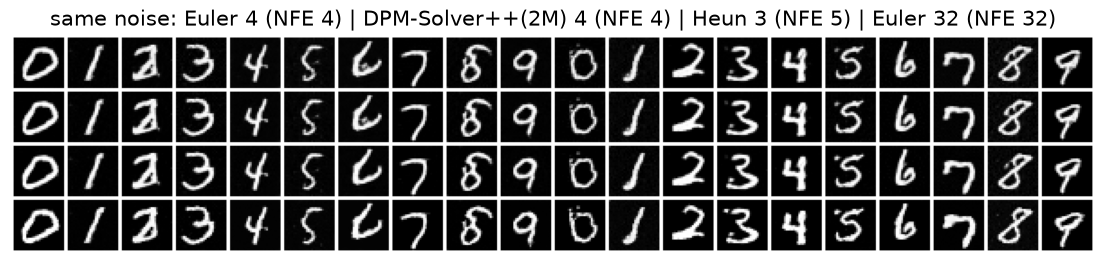

In [15]:
rows = [IMGS[("euler", 4)][:20], IMGS[("dpm", 4)][:20], IMGS[("heun", 3)][:20], IMGS[("euler", 32)][:20]]
show(torch.cat(rows), nrow=20, scale=0.9,
     title="same noise: Euler 4 (NFE 4) | DPM-Solver++(2M) 4 (NFE 4) | Heun 3 (NFE 5) | Euler 32 (NFE 32)")

**Что видно.** Во всех четырёх строках из одного шума получаются одни и те же цифры одного стиля. ODE детерминирована, и все решатели приближают одно и то же отображение «шум → изображение», поэтому различаются только детали. Различаются только мелкие детали штрихов. Это свойство (одинаковый результат при разных решателях) и используют reflow и дистилляция: у отображения есть конкретная цель, которую можно выучить.

## 13. MNIST: reflow

### 13.1. Пары и дообучение

Пары для reflow строятся базовой моделью: $\epsilon \sim \mathcal{N}(0, I)$, случайный класс $y$ и $\hat x_0 = \mathrm{ODE}(\epsilon \mid y)$, решённая DPM-Solver++(2M) за 10 шагов (качество по разделу 12 близко к эталонному, а стоимость в 6 раз ниже, чем у Heun с 33 шагами). Модель 2-RF инициализируется весами базовой и дообучается функцией потерь flow matching на этих парах, как в [Liu et al. (2023)](https://arxiv.org/abs/2209.03003). Стоимость reflow складывается из генерации пар и дообучения; обе части входят в `TRAIN_COST`.

In [16]:
@torch.no_grad()
def make_pairs_mnist(model, n, steps=10, seed=77):
    g = torch.Generator().manual_seed(seed); E, X, Y = [], [], []
    for i in range(0, n, GEN_BS):
        b = min(GEN_BS, n - i)
        eps = torch.randn(b, 1, 28, 28, generator=g).to(DEVICE); y = torch.randint(0, 10, (b,), generator=g).to(DEVICE)
        x0 = dpmpp2m(lambda x, t: model(x, t, y), eps, t_grid(steps).float())
        E.append(eps.cpu()); X.append(x0.clamp(-1, 1).cpu()); Y.append(y.cpu())
    return torch.cat(E), torch.cat(X), torch.cat(Y)

with Timer() as tm_p: PAIRS = make_pairs_mnist(BASE, S["n_pairs"])
print(f"{S['n_pairs']} pairs (DPM-Solver++(2M), 10 steps): {tm_p.s:.0f} s")

def pair_batches(steps, bs, seed=0):
    g = torch.Generator().manual_seed(seed)
    for _ in range(steps):
        j = torch.randint(0, len(PAIRS[0]), (bs,), generator=g)
        yield (PAIRS[1][j].to(DEVICE), PAIRS[0][j].to(DEVICE)), PAIRS[2][j].to(DEVICE)

def reflow_loss(model, x0_eps, y):
    x0, eps = x0_eps; t = torch.rand(len(x0), device=DEVICE); tt = t.view(-1, 1, 1, 1)
    return F.mse_loss(model((1 - tt) * x0 + tt * eps, t, y), eps - x0)

with Timer() as tm_r:
    RF2_M, H_RF2 = train_loop(copy.deepcopy(BASE), S["steps_reflow"], reflow_loss, lr=2e-4, warm=50, seed=3,
                              data=pair_batches(S["steps_reflow"], S["bs"]))
TRAIN_COST["reflow (2-RF)"] = tm_p.s + tm_r.s
print(f"2-RF: {S['steps_reflow']} steps in {tm_r.s / 60:.1f} min; loss first {H_RF2[0][1]:.4f}, last {H_RF2[-1][1]:.4f}")

6000 pairs (DPM-Solver++(2M), 10 steps): 96 s


2-RF: 600 steps in 3.1 min; loss first 0.0396, last 0.0141


**Что видно.** 6000 пар заняли 96 с (DPM++ 10 шагов), дообучение 2-RF — 3,1 мин на 600 шагов. Потеря упала с 0,040 до 0,014, в 12 раз ниже, чем у базовой модели (0,174). Для детерминированных пар условная дисперсия почти исчезает, и регрессия на $x_1 - x_0$ становится почти точной.

### 13.2. Прямота траекторий и генерация за несколько шагов

Прямота $S$ из раздела 10.2 считается по 50-шаговым траекториям Эйлера для 100 изображений и делится на $\mathbb{E}\|x_1 - x_0\|^2$, чтобы не зависеть от масштаба. Затем 2-RF сравнивается с базовой моделью при 1, 2, 4 и 8 шагах Эйлера.

base (1-RF)  normalized straightness S / E|x1 - x0|^2 = 0.0355


2-RF         normalized straightness S / E|x1 - x0|^2 = 0.0037


2-RF, Euler, 1 steps                  NFE=   1  time=   0.8 s  FD=  7.76  acc=0.950  div=0.816  conf=0.915


2-RF, Euler, 2 steps                  NFE=   2  time=   1.6 s  FD=  5.11  acc=0.938  div=0.853  conf=0.915


2-RF, Euler, 4 steps                  NFE=   4  time=   3.1 s  FD=  4.26  acc=0.936  div=0.870  conf=0.915


2-RF, Euler, 8 steps                  NFE=   8  time=   6.2 s  FD=  3.82  acc=0.932  div=0.879  conf=0.914


2-RF, DPM-Solver++(2M), 4 steps       NFE=   4  time=   3.1 s  FD=  4.21  acc=0.936  div=0.872  conf=0.915


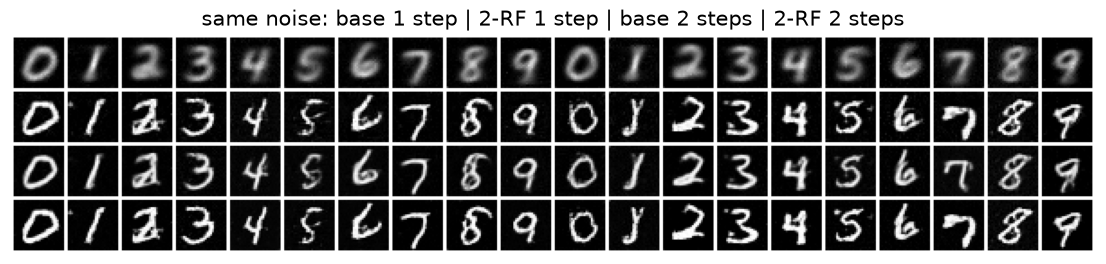

In [17]:
@torch.no_grad()
def straightness_img(model, n=100, steps=50):
    x1, y = X1_EVAL[:n].to(DEVICE), Y_EVAL[:n].to(DEVICE); ts = t_grid(steps).float()
    x, acc = x1, 0.0; us = []
    for t, s in zip(ts[:-1], ts[1:]):
        u = model(x, _tb(x, t), y); us.append(u); x = x + (s - t) * u
    disp = x1 - x
    Sv = torch.stack([((u - disp) ** 2).flatten(1).sum(1) for u in us]).mean().item()
    return Sv / (disp ** 2).flatten(1).sum(1).mean().item()

for name, m in [("base (1-RF)", BASE), ("2-RF", RF2_M)]: print(f"{name:12s} normalized straightness S / E|x1 - x0|^2 = {straightness_img(m):.4f}")
for n in [1, 2, 4, 8]:
    IMGS[("rf2", n)] = run(f"2-RF, Euler, {n} steps", "2-RF + Euler", n, solver_fn(RF2_M, euler, n))
_ = run("2-RF, DPM-Solver++(2M), 4 steps", "2-RF + DPM-Solver++", 4, solver_fn(RF2_M, dpmpp2m, 4))
show(torch.cat([IMGS[("euler", 1)][:20], IMGS[("rf2", 1)][:20], IMGS[("euler", 2)][:20], IMGS[("rf2", 2)][:20]]), nrow=20, scale=0.9,
     title="same noise: base 1 step | 2-RF 1 step | base 2 steps | 2-RF 2 steps")

**Что видно.** Нормированная кривизна упала в 10 раз: с 0,036 у базовой модели до 0,0037 у 2-RF. У MNIST траектории изначально заметно прямее, чем у двумерной смеси, но выигрыш при малом NFE огромный. Один шаг 2-RF даёт FD 7,76 против 174,7 у базовой модели, два шага — 5,11 против 36,9, четыре — 4,26 против 9,78. При 8 шагах 2-RF (3,82) лишь немного лучше базовой модели с Эйлером (4,06) и хуже базовой с DPM++ (2,48). Как и в 2D, у 2-RF есть собственный потолок, заданный качеством пар и коротким дообучением. Высший порядок 2-RF уже почти не помогает: DPM++ за 4 шага даёт 4,21 против 4,26 у Эйлера, потому что траектории прямые. Точность класса у 2-RF ниже (0,93–0,95), но совпадает с уровнем настоящих изображений (0,944). У базовой модели при малом NFE она выше, 0,96–0,99, при пониженном разнообразии. На картинке видно то же: у базовой модели 1 шаг даёт размытые средние цифры, у 2-RF — чёткие цифры того же стиля, что и в последней строке.

## 14. MNIST: progressive distillation

В каждом раунде ученик учится одним шагом повторять два шага учителя (раздел 6.2). Для линейного пути и шага Эйлера (то есть DDIM) цель особенно проста: ученик в точке $x_t$ должен выдать среднюю скорость двух шагов учителя,
$
u^{*} = \frac{x_t - x_s^{\text{teacher}}}{t - s},\qquad x_s^{\text{teacher}} = \text{Euler}\big(\text{Euler}(x_t;\ t \to m);\ m \to s\big).
$
Это равносильно цели для $\hat x_0$ из [Salimans & Ho (2022)](https://arxiv.org/abs/2202.00512): $\tilde x_0 = (t\,x_s - s\,x_t)/(t - s)$. Точки $x_t$ строятся из настоящих данных, $t$ выбирается из сетки ученика. Первый учитель — базовая модель с `pd_start` шагами Эйлера, ученик инициализируется весами учителя, и после каждого раунда число шагов вдвое меньше.

round -> 4 step(s): 250 iterations in 2.2 min, loss 0.0025 -> 0.0005


PD student, 4 step(s)                 NFE=   4  time=   3.5 s  FD=  4.49  acc=0.956  div=0.845  conf=0.919


round -> 2 step(s): 250 iterations in 2.2 min, loss 0.0092 -> 0.0016


PD student, 2 step(s)                 NFE=   2  time=   1.9 s  FD=  5.46  acc=0.952  div=0.832  conf=0.919


round -> 1 step(s): 250 iterations in 2.2 min, loss 0.0283 -> 0.0064


PD student, 1 step(s)                 NFE=   1  time=   1.0 s  FD=  7.55  acc=0.956  div=0.801  conf=0.916


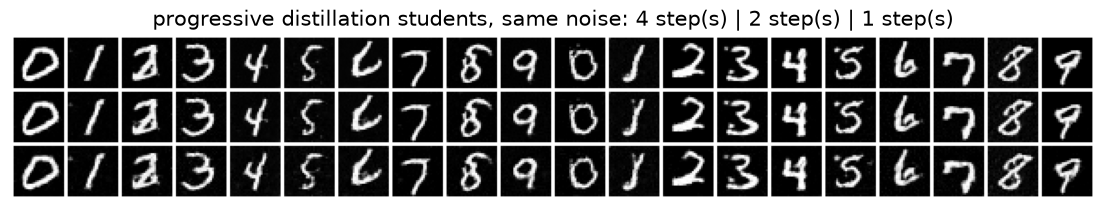

In [18]:
def pd_round(teacher, n_student, steps, seed):
    ts = t_grid(2 * n_student).float().to(DEVICE)                            # сетка учителя; у ученика каждый второй узел
    def loss_fn(model, x0, y):
        k = torch.randint(0, n_student, (len(x0),), device=DEVICE)
        t, m, s = ts[2 * k], ts[2 * k + 1], ts[2 * k + 2]
        tt, mm, ss = (v.view(-1, 1, 1, 1) for v in (t, m, s))
        xt = (1 - tt) * x0 + tt * torch.randn_like(x0)
        with torch.no_grad():
            xm = xt + (mm - tt) * teacher(xt, t, y)
            xs = xm + (ss - mm) * teacher(xm, m, y)
        return F.mse_loss(model(xt, t, y), (xt - xs) / (tt - ss))
    return train_loop(copy.deepcopy(teacher), steps, loss_fn, lr=2e-4, warm=50, seed=seed, ema_decay=0.995)

PD = {}; teacher = BASE; n = S["pd_start"]; t_pd = 0.0
while n > 1:
    n //= 2
    with Timer() as tm: teacher, h = pd_round(teacher, n, S["steps_pd"], seed=100 + n)
    PD[n] = teacher; t_pd += tm.s
    print(f"round -> {n} step(s): {S['steps_pd']} iterations in {tm.s / 60:.1f} min, loss {h[0][1]:.4f} -> {h[-1][1]:.4f}")
    IMGS[("pd", n)] = run(f"PD student, {n} step(s)", "progressive distillation", n, solver_fn(teacher, euler, n))
TRAIN_COST["progressive distillation"] = t_pd
show(torch.cat([IMGS[("pd", k)][:20] for k in sorted(PD, reverse=True)]), nrow=20, scale=0.9,
     title="progressive distillation students, same noise: " + " | ".join(f"{k} step(s)" for k in sorted(PD, reverse=True)))

**Что видно.** Каждый раунд занимает около 2,2 мин (250 итераций), и потеря в каждом падает в 4–6 раз. С каждым раундом цель труднее: потеря в конце раунда растёт с 0,0005 до 0,0016 и 0,0064. Ученики дают FD 4,49 / 5,46 / 7,55 при 4 / 2 / 1 шаге против 9,78 / 36,9 / 174,7 у базовой модели с тем же числом шагов Эйлера. Ошибки раундов накапливаются, поэтому один шаг PD хуже четырёх. Учитель первого раунда — Euler 8 шагов (FD 4,06), и ученик на 4 шагах почти сохраняет его качество. На картинке все три ученика из одного шума рисуют одни и те же цифры: PD сохраняет отображение учителя и меняет только число шагов, за которое оно вычисляется.

## 15. MNIST: consistency distillation

Модель согласованности $f_\theta(x_t, t)$ переводит любую точку траектории ОДУ в её начало $x_0$ (раздел 6.3). Граничное условие $f_\theta(x, 0) = x$ встраиваем в параметризацию: $f_\theta(x, t) = x - t\,F_\theta(x, t)$. Это $c_{\text{skip}}(t) = 1$, $c_{\text{out}}(t) = -t$ в обозначениях [Song et al. (2023)](https://arxiv.org/abs/2303.01469), и при $F_\theta = u_\theta$ это просто одношаговый DDIM. Поэтому ученика естественно инициализировать базовой моделью.

Обучение (consistency distillation):

1. берём сетку $0 = t_0 < t_1 < \dots < t_N = 1$ с $N = 18$ и случайное $n$;
2. строим $x_{t_{n+1}} = (1 - t_{n+1})x_0 + t_{n+1}\epsilon$;
3. учитель делает один шаг Эйлера до $t_n$: $\hat x_{t_n}$;
4. минимизируем $d\big(f_\theta(x_{t_{n+1}}, t_{n+1}),\ f_{\theta^-}(\hat x_{t_n}, t_n)\big)$, где $\theta^-$ — EMA весов ученика с $\mu = 0{,}95$, а $d$ — псевдо-Хьюбер $\sqrt{\|a - b\|^2 + c^2} - c$ с $c = 0{,}00054\sqrt{d}$ ([Song & Dhariwal, 2023](https://arxiv.org/abs/2310.14189)).

Многошаговая генерация (алгоритм 1 Song et al.): $\hat x_0 = f(x_1, 1)$, затем для $\tau = \tau_2, \tau_3, \dots$ заново зашумляем $x_\tau = (1 - \tau)\hat x_0 + \tau z$ и снова применяем $f$.

consistency distillation: 800 steps in 7.1 min, loss 0.455 -> 0.486


CM, 1 step(s)                         NFE=   1  time=   0.9 s  FD=  5.42  acc=0.938  div=0.852  conf=0.912


CM, 2 step(s)                         NFE=   2  time=   1.8 s  FD=  2.93  acc=0.952  div=0.853  conf=0.925


CM, 3 step(s)                         NFE=   3  time=   2.6 s  FD=  2.76  acc=0.958  div=0.854  conf=0.928


CM, 4 step(s)                         NFE=   4  time=   3.5 s  FD=  2.33  acc=0.960  div=0.856  conf=0.924


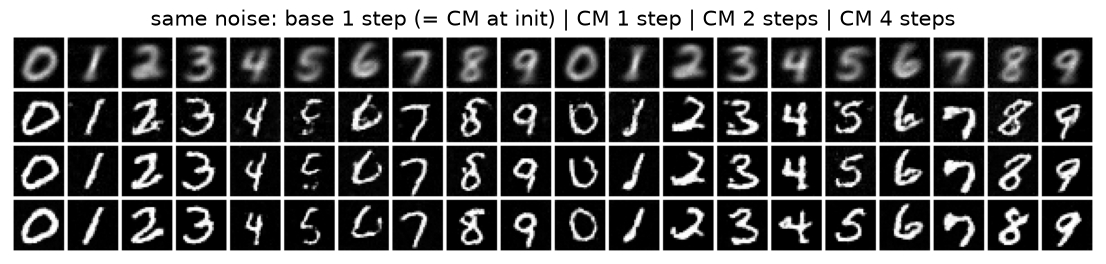

In [19]:
N_CD = 18
TS_CD = torch.linspace(0, 1, N_CD + 1, device=DEVICE)
HUBER_C = 0.00054 * math.sqrt(28 * 28)

def cm_f(model, x, t, y): return x - t.view(-1, 1, 1, 1) * model(x, t, y)

def train_cd(student, teacher, steps, mu=0.95, seed=0):
    target = copy.deepcopy(student).eval().requires_grad_(False)
    def loss_fn(model, x0, y):
        n = torch.randint(0, N_CD, (len(x0),), device=DEVICE)
        t1, t0 = TS_CD[n + 1], TS_CD[n]; tt1, tt0 = t1.view(-1, 1, 1, 1), t0.view(-1, 1, 1, 1)
        x1 = (1 - tt1) * x0 + tt1 * torch.randn_like(x0)
        with torch.no_grad():
            x_prev = x1 + (tt0 - tt1) * teacher(x1, t1, y)                    # один шаг учителя по ОДУ
            tgt = cm_f(target, x_prev, t0, y)
        d2 = ((cm_f(model, x1, t1, y) - tgt) ** 2).flatten(1).sum(1)
        loss = ((d2 + HUBER_C ** 2).sqrt() - HUBER_C).mean()
        with torch.no_grad():                                                 # theta^- <- mu theta^- + (1 - mu) theta
            for pt, p in zip(target.parameters(), model.parameters()): pt.lerp_(p, 1 - mu)
        return loss
    return train_loop(student, steps, loss_fn, lr=2e-4, warm=50, seed=seed, ema_decay=0.995)

with Timer() as tm: CM, H_CM = train_cd(copy.deepcopy(BASE), BASE, S["steps_cd"], seed=7)
TRAIN_COST["consistency distillation"] = tm.s
print(f"consistency distillation: {S['steps_cd']} steps in {tm.s / 60:.1f} min, loss {H_CM[0][1]:.3f} -> {H_CM[-1][1]:.3f}")

def cm_sampler(model, taus):
    def f(x1, y, gen):
        x0 = cm_f(model, x1, torch.ones(len(x1), device=DEVICE), y)
        for tau in taus[1:]:
            xt = (1 - tau) * x0 + tau * torch.randn(x0.shape, generator=gen, device=DEVICE)
            x0 = cm_f(model, xt, torch.full((len(x1),), tau, device=DEVICE), y)
        return x0
    return f

CM_TAUS = {1: [1.0], 2: [1.0, 0.5], 3: [1.0, 0.6, 0.3], 4: [1.0, 0.75, 0.5, 0.25]}
for k, taus in CM_TAUS.items():
    IMGS[("cm", k)] = run(f"CM, {k} step(s)", "consistency distillation", k, cm_sampler(CM, taus))
show(torch.cat([IMGS[("euler", 1)][:20]] + [IMGS[("cm", k)][:20] for k in [1, 2, 4]]), nrow=20, scale=0.9,
     title="same noise: base 1 step (= CM at init) | CM 1 step | CM 2 steps | CM 4 steps")

**Что видно.** Потеря consistency distillation за 7,1 мин не уменьшилась (0,455 → 0,486). Так и должно быть: цель $f_{\theta^-}$ — подвижная EMA самого ученика, и по мере того как ученик «отрывается» от одношагового DDIM, расстояния между предсказаниями на соседних $t$ могут расти. По потере CD нельзя судить о качестве, нужна внешняя метрика. По ней результат лучший в лекции при малом NFE. Один шаг даёт FD 5,42 (базовая модель 174,7, 2-RF 7,76, PD 7,55), два — 2,93, четыре — 2,33, что лучше базовой модели с DPM++ за 8 NFE (2,48). На картинке первая строка — базовая модель за 1 шаг, то есть CM до обучения. Уже после 800 шагов ученик делает из того же шума чёткие цифры. Многошаговая CM меняет детали и даже стиль цифр: каждый дополнительный шаг заново зашумляет $\hat x_0$ свежим шумом, поэтому результат не обязан совпадать с одношаговым.

## 16. Сравнение при равном NFE и Парето-фронт

### 16.1. Качество от NFE

Все запуски разделов 12–15 на одном графике. Слева FD (меньше — лучше), справа точность класса. Горизонтальная линия — FD 500 настоящих тестовых изображений: это «пол» метрики при таком размере выборки.

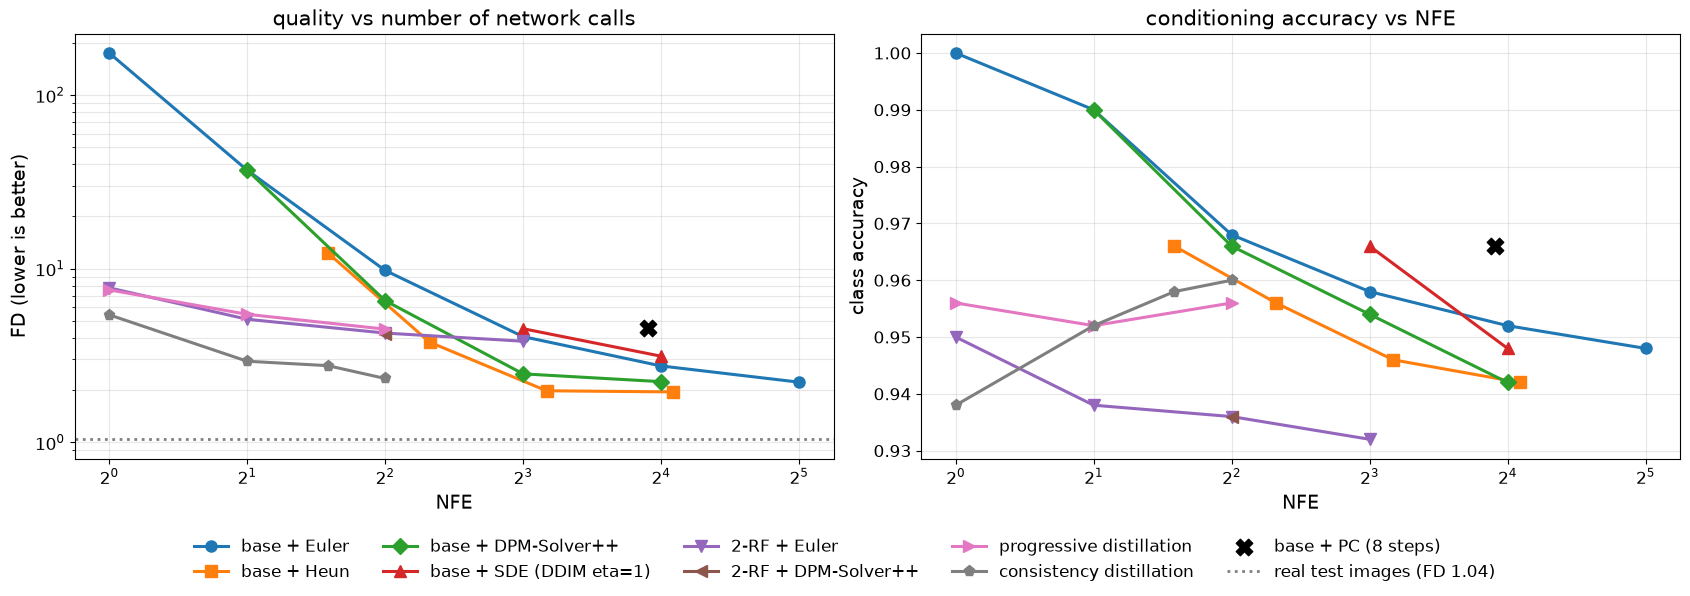

 NFE              base + Euler               base + Heun       base + DPM-Solver++           base + SDE / PC              2-RF + Euler       2-RF + DPM-Solver++  progressive distillation  consistency distillation
   1                    174.66                         -                         -                         -                      7.76                         -                      7.55                      5.42
   2                     36.92                         -                     36.92                         -                      5.11                         -                      5.46                      2.93
   3                         -                     12.32                         -                         -                         -                         -                         -                      2.76
   4                      9.78                         -                      6.55                         -                      4.26              

In [20]:
FLOOR = base_real["FD"]
methods = list(dict.fromkeys(r["method"] for r in RESULTS.values()))
STYLE = {m: (c, mk) for m, c, mk in zip(methods, plt.cm.tab10.colors, "osD^v<>pXh*")}
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
for m in methods:
    rr = sorted([r for k, r in RESULTS.items() if r["method"] == m and "shift" not in k and "reference" not in k and "PC" not in k], key=lambda r: r["NFE"])
    if not rr: continue
    c, mk = STYLE[m]
    for a, key in zip(ax, ["FD", "acc"]):
        a.plot([r["NFE"] for r in rr], [r[key] for r in rr], marker=mk, color=c, lw=2.2, ms=8, label=m.replace("SDE / PC", "SDE (DDIM eta=1)"))
for k, r in RESULTS.items():                                                  # predictor-corrector: отдельная точка
    if "PC" in k:
        for a, key in zip(ax, ["FD", "acc"]):
            a.scatter(r["NFE"], r[key], marker="X", s=140, color="black", zorder=5, label="base + PC (8 steps)" if key == "FD" else None)
ax[0].axhline(FLOOR, color="gray", ls=":", lw=2, label=f"real test images (FD {FLOOR:.2f})")
ax[0].set_yscale("log"); ax[0].set_ylabel("FD (lower is better)", fontsize=14); ax[1].set_ylabel("class accuracy", fontsize=14)
for a in ax: a.set_xscale("log", base=2); a.set_xlabel("NFE", fontsize=14); a.grid(alpha=0.3, which="both"); a.tick_params(labelsize=12)
ax[0].set_title("quality vs number of network calls", fontsize=15); ax[1].set_title("conditioning accuracy vs NFE", fontsize=15)
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=12, frameon=False)
plt.tight_layout(rect=(0, 0.11, 1, 1)); plt.show()

print(f"{'NFE':>4s}  " + "  ".join(f"{m[:24]:>24s}" for m in methods))
for nfe in [1, 2, 3, 4, 5, 8, 9, 16]:
    cells = []
    for m in methods:
        rr = [r for k, r in RESULTS.items() if r["method"] == m and r["NFE"] == nfe and "shift" not in k]
        cells.append(f"{min(r['FD'] for r in rr):24.2f}" if rr else f"{'-':>24s}")
    print(f"{nfe:4d}  " + "  ".join(cells))

**Что видно.** При равном NFE до 4 включительно все ускоренные методы на порядок лучше базовой модели. При 1 NFE CM даёт 5,42, PD 7,55, 2-RF 7,76, а базовая модель 174,7. При 4 NFE CM даёт 2,33, 2-RF 4,21–4,26, PD 4,49, а лучшая базовая (DPM++) 6,55. Уже при 5 NFE базовая модель с Heun (3,78) обгоняет 2-RF и PD, при 8–9 NFE DPM++ и Heun (2,48 и 1,98) обгоняют все ускоренные методы. CM лучше всех при любом NFE ≤ 4, но её кривая выходит на 2,3 и ниже не идёт: ученик ограничен качеством учителя и коротким обучением. На правом графике точность класса у базовой модели при малом NFE выше, чем у данных (0,944), что отражает пониженное разнообразие, а не лучшее качество.

### 16.2. Парето-фронт «качество — время»

Конфигурация лежит на Парето-фронте, если нет другой, которая одновременно быстрее и не хуже по FD. На оси $x$ время генерации всей выборки на этом устройстве, на оси $y$ FD. Время обучения дистиллированных моделей здесь не учитывается; оно разобрано в разделе 16.3.

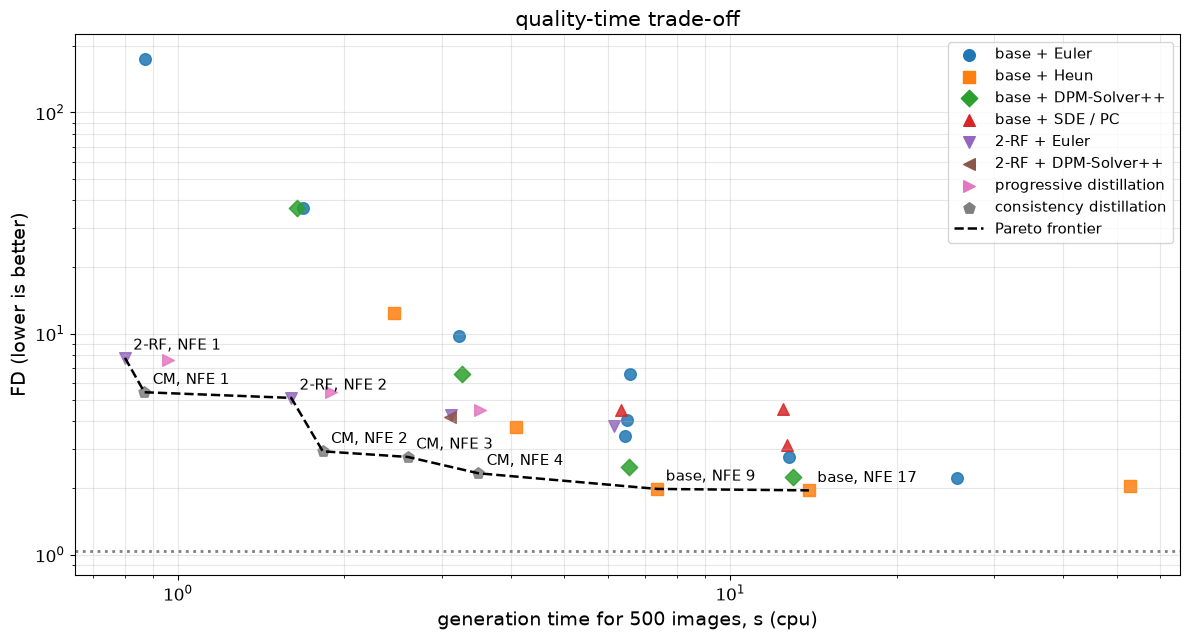

Pareto frontier:
  2-RF, Euler, 1 steps                  NFE=  1  time=   0.8 s  FD=  7.76  acc=0.950
  CM, 1 step(s)                         NFE=  1  time=   0.9 s  FD=  5.42  acc=0.938
  2-RF, Euler, 2 steps                  NFE=  2  time=   1.6 s  FD=  5.11  acc=0.938
  CM, 2 step(s)                         NFE=  2  time=   1.8 s  FD=  2.93  acc=0.952
  CM, 3 step(s)                         NFE=  3  time=   2.6 s  FD=  2.76  acc=0.958
  CM, 4 step(s)                         NFE=  4  time=   3.5 s  FD=  2.33  acc=0.960
  base, Heun, 5 steps                   NFE=  9  time=   7.4 s  FD=  1.98  acc=0.946
  base, Heun, 9 steps                   NFE= 17  time=  13.9 s  FD=  1.95  acc=0.942
time per network call for 500 images: 0.81 s (median)


In [21]:
pts = sorted(((r["time"], r["FD"], k) for k, r in RESULTS.items()), key=lambda p: (p[0], p[1]))
front, best = [], float("inf")
for tsec, fd, k in pts:
    if fd < best: front.append((tsec, fd, k)); best = fd
fig, ax = plt.subplots(figsize=(12, 6.5))
for k, r in RESULTS.items():
    c, mk = STYLE[r["method"]]; ax.scatter(r["time"], r["FD"], color=c, marker=mk, s=70, alpha=0.85)
for m in methods: ax.scatter([], [], color=STYLE[m][0], marker=STYLE[m][1], s=70, label=m)
ax.plot([p[0] for p in front], [p[1] for p in front], "k--", lw=1.8, label="Pareto frontier")
for tsec, fd, k in front: ax.annotate(k.split(", ", 1)[0] + ", NFE " + str(RESULTS[k]["NFE"]), (tsec, fd), textcoords="offset points", xytext=(6, 6), fontsize=10.5)
ax.axhline(FLOOR, color="gray", ls=":", lw=2)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(f"generation time for {S['n_eval']} images, s ({DEVICE})", fontsize=14)
ax.set_ylabel("FD (lower is better)", fontsize=14); ax.set_title("quality-time trade-off", fontsize=15)
ax.legend(fontsize=10.5, loc="upper right"); ax.grid(alpha=0.3, which="both"); ax.tick_params(labelsize=12)
plt.tight_layout(); plt.show()
print("Pareto frontier:")
for tsec, fd, k in front: print(f"  {k:37s} NFE={RESULTS[k]['NFE']:3d}  time={tsec:6.1f} s  FD={fd:6.2f}  acc={RESULTS[k]['acc']:.3f}")
print(f"time per network call for {S['n_eval']} images: {np.median([r['time'] / r['NFE'] for r in RESULTS.values() if r['NFE'] >= 4]):.2f} s (median)")

**Что видно.** Парето-фронт ломаный, как и предсказывает раздел 7.2. До 4 NFE (≤ 3,5 с на 500 изображений) его образует CM. Дальше начинается базовая модель с Heun: 9 NFE (7,4 с, FD 1,98) и 17 NFE (13,9 с, FD 1,95). DPM++, Эйлер, SDE и PD фронту не принадлежат. Две точки 2-RF (1 и 2 NFE) попали на фронт только из-за шума замера времени: при равном NFE вызов сети стоит одинаково (около 0,8 с), а 2-RF оказался быстрее CM на 0,05–0,2 с при худшем FD. Сравнивать время точнее, чем до одного вызова сети, на CPU бессмысленно.

### 16.3. Стоимость обучения и окупаемость

Дистилляция и reflow ускоряют генерацию, но стоят дополнительного обучения. Чтобы сравнить честно, найдём для каждого ускоренного метода его лучшую конфигурацию с NFE ≤ 4. Затем найдём самую дешёвую конфигурацию базовой модели с любым решателем, которая не хуже её по FD. Разница во времени генерации на одно изображение, делённая на время дополнительного обучения, показывает, после скольких изображений метод окупается.

In [22]:
base_runs = [(r["time"] / S["n_eval"], r["FD"], k) for k, r in RESULTS.items() if r["method"].startswith("base")]
print(f"{'method':28s} {'extra training':>15s} {'best NFE<=4':>30s} {'base config with same FD':>36s} {'break-even':>14s}")
for m, cost in [(k, v) for k, v in TRAIN_COST.items() if k != "base flow matching"]:
    key = {"reflow (2-RF)": "2-RF", "progressive distillation": "PD", "consistency distillation": "CM"}[m]
    cand = [(r["FD"], k) for k, r in RESULTS.items() if k.startswith(key) and r["NFE"] <= 4]
    fd, k = min(cand); per_img = RESULTS[k]["time"] / S["n_eval"]
    ok = [b for b in base_runs if b[1] <= fd]
    if ok:
        bt, bfd, bk = min(ok); gain = bt - per_img
        be = f"{cost / gain:,.0f} images" if gain > 0 else "never"
        print(f"{m:28s} {cost / 60:12.1f} min {k + f' (FD {fd:.2f})':>30s} {bk + f' (FD {bfd:.2f})':>36s} {be:>14s}")
    else:
        print(f"{m:28s} {cost / 60:12.1f} min {k + f' (FD {fd:.2f})':>30s} {'no base config reaches this FD':>36s} {'-':>14s}")
print(f"\nbase model training: {TRAIN_COST['base flow matching'] / 60:.1f} min")

method                        extra training                    best NFE<=4             base config with same FD     break-even
reflow (2-RF)                         4.7 min 2-RF, DPM-Solver++(2M), 4 steps (FD 4.21)        base, Heun, 3 steps (FD 3.78) 141,184 images
progressive distillation              6.6 min PD student, 4 step(s) (FD 4.49)        base, Heun, 3 steps (FD 3.78) 344,170 images
consistency distillation              7.1 min        CM, 4 step(s) (FD 2.33)        base, Heun, 5 steps (FD 1.98)  54,646 images

base model training: 10.1 min


**Что видно.** Самая быстрая окупаемость у consistency distillation. 7,1 мин дообучения окупаются примерно через 55 тысяч изображений по сравнению с базовой моделью с Heun за 9 NFE. Это сравнение даже несколько льготное для CM: у Heun FD лучше, 1,98 против 2,33. Reflow (4,7 мин вместе с генерацией пар) окупается через 141 тысячу изображений, PD (6,6 мин) — через 344 тысячи. Их лучшие конфигурации с NFE ≤ 4 (FD 4,2–4,5) экономят всего 1–2 вызова по сравнению с Heun за 5 NFE (FD 3,78). Абсолютные числа зависят от устройства и размера модели. Но вывод общий: дистилляция выгодна, когда генераций очень много (сервис) или нужна генерация в реальном времени. Для одного эксперимента лучший решатель бесплатен и почти так же хорош.

## 17. Сводная таблица

In [23]:
print(f"{'configuration':36s} {'NFE':>4s} {'time, s':>8s} {'FD':>7s} {'acc':>6s} {'div':>6s} {'conf':>6s}")
for k, r in sorted(RESULTS.items(), key=lambda kv: (kv[1]["NFE"], kv[1]["FD"])):
    print(f"{k:36s} {r['NFE']:4d} {r['time']:8.1f} {r['FD']:7.2f} {r['acc']:6.3f} {r['div']:6.3f} {r['conf']:6.3f}")
print(f"{'real test images':36s} {'-':>4s} {'-':>8s} {base_real['FD']:7.2f} {base_real['acc']:6.3f} {base_real['div']:6.3f} {base_real['conf']:6.3f}")
print(f"\ntraining time: " + ", ".join(f"{k} {v / 60:.1f} min" for k, v in TRAIN_COST.items()))
print(f"notebook run time: {(time.time() - T_START) / 60:.1f} min on {DEVICE}")

configuration                         NFE  time, s      FD    acc    div   conf
CM, 1 step(s)                           1      0.9    5.42  0.938  0.852  0.912
PD student, 1 step(s)                   1      1.0    7.55  0.956  0.801  0.916
2-RF, Euler, 1 steps                    1      0.8    7.76  0.950  0.816  0.915
base, Euler (DDIM), 1 steps             1      0.9  174.66  1.000  0.181  0.912
CM, 2 step(s)                           2      1.8    2.93  0.952  0.853  0.925
2-RF, Euler, 2 steps                    2      1.6    5.11  0.938  0.853  0.915
PD student, 2 step(s)                   2      1.9    5.46  0.952  0.832  0.919
base, Euler (DDIM), 2 steps             2      1.7   36.92  0.990  0.585  0.948
base, DPM-Solver++(2M), 2 steps         2      1.6   36.92  0.990  0.585  0.948
CM, 3 step(s)                           3      2.6    2.76  0.958  0.854  0.928
base, Heun, 2 steps                     3      2.5   12.32  0.966  0.740  0.938
CM, 4 step(s)                           

**Что видно.** Таблица отсортирована по NFE. При 1–4 NFE лидирует CM (FD 5,42 → 2,33), при 5–17 — базовая модель с Heun (3,78 → 1,95). Базовая модель с Эйлером приближается к ним только к 32 NFE (2,22). Лучший FD всей лекции 1,95, что примерно в 2 раза выше «пола» настоящих изображений (1,04). Обучение заняло: базовая модель 10,1 мин, reflow 4,7, PD 6,6, CD 7,1 мин. Весь блокнот на CPU выполнился за 34,5 мин. На GPU-ветке модели больше и обучаются дольше, её результаты здесь не проверены.

# Выводы

1. Скорость генерации определяется числом вызовов сети (NFE). Сокращают его тремя способами: лучший решатель, более прямые траектории, дистилляция. Сравнивать методы нужно при равном NFE, а с учётом стоимости обучения — по Парето-фронту.
2. DDIM — это метод Эйлера (точнее, экспоненциальный интегратор первого порядка) для probability flow ODE. Для линейного пути он буквально совпадает с Эйлером, а для другого расписания — с Эйлером на перенесённой сетке. В 2D совпадение проверено до $10^{-13}$.
3. Порядок решателя проявляется только асимптотически. Heun выходит на второй порядок с 33 NFE, а при 9 NFE в 2D он хуже Эйлера. DPM-Solver++(2M) даёт второй порядок за один вызов на шаг. На MNIST он лучше Эйлера при любом NFE ≥ 4 (6,55 против 9,78 при 4 NFE, 2,48 против 4,06 при 8), но на равномерной сетке по $t$ выходит на плато.
4. Стохастические сэмплеры и predictor-corrector при фиксированном NFE хуже ODE-решателей: SDE за 8 шагов дал FD 4,51, а PC за 15 NFE — 4,57 против 4,06 у Эйлера за 8. Сетка времени важна не меньше решателя: сдвиг к шуму улучшил FD Эйлера с 8 шагами с 4,06 до 3,43.
5. Conditional flow matching обучает маргинальное поле, никогда его не видя. Градиенты CFM и FM совпадают, и в 2D выученное поле совпало с точным с косинусом 0,94–1,00.
6. Маргинальные траектории 1-RF искривлены ($S = 1{,}10$ в 2D), потому что независимые прямые пересекаются. Один reflow выпрямляет их ($S = 0{,}003$), и транспортная стоимость при этом не растёт. На MNIST один шаг 2-RF дал FD 7,76 вместо 174,7, но при 8 шагах 2-RF упирается в собственный потолок (3,82).
7. Progressive distillation сохраняет отображение учителя и вдвое сокращает число шагов за раунд, но ошибки раундов накапливаются: FD 4,49 / 5,46 / 7,55 при 4 / 2 / 1 шаге.
8. Consistency distillation дала лучшее качество при малом NFE: 5,42 за 1 шаг и 2,33 за 4. Это лучше базовой модели с DPM++ за 8 NFE. Ниже 2,3 она не опускается, и потеря CD о качестве не говорит.
9. На Парето-фронте при бюджете до 4 NFE стоит CM, при 9–17 NFE — базовая модель с Heun. На CPU CD окупилась примерно через 55 тысяч изображений, reflow через 141 тысячу, PD через 344 тысячи. Для разового эксперимента лучший решатель бесплатен и почти так же хорош.
10. Все числа получены на CPU в режиме `FAST_DEV_RUN` за 34,5 мин, FD посчитан на 500 образцах с «полом» 1,04. Ветка GPU не проверялась.

# Контрольные вопросы

1. Запишите probability flow ODE для пути $\alpha_t = 1 - t$, $\sigma_t = t$ через $\hat\epsilon$ и покажите, что её правая часть равна $\hat\epsilon - \hat x_0$.
   Ответ: $\dot\alpha/\alpha = -1/(1 - t)$, $\dot\sigma - \sigma\dot\alpha/\alpha = 1 + t/(1 - t) = 1/(1 - t)$. Значит, $\dot x = (\hat\epsilon - x)/(1 - t)$. Подставляя $x = (1 - t)\hat x_0 + t\hat\epsilon$, получаем $\hat\epsilon - x = (1 - t)(\hat\epsilon - \hat x_0)$, откуда $\dot x = \hat\epsilon - \hat x_0$.
2. Сеть предсказала скорость $v = 0{,}4$ в точке $x_t = 0{,}2$ при $t = 0{,}5$. Найдите $\hat x_0$, $\hat\epsilon$ и результат шага DDIM до $s = 0{,}25$.
   Ответ: $\hat x_0 = 0{,}2 - 0{,}5\cdot 0{,}4 = 0$, $\hat\epsilon = 0{,}2 + 0{,}5\cdot 0{,}4 = 0{,}4$. DDIM: $x_s = 0{,}75\cdot 0 + 0{,}25\cdot 0{,}4 = 0{,}1$. Эйлер: $0{,}2 + (0{,}25 - 0{,}5)\cdot 0{,}4 = 0{,}1$, то же самое.
3. В какую точку $\tau$ линейного пути переходит точка VP-расписания с $\alpha = 0{,}8$, $\sigma = 0{,}6$?
   Ответ: $\tau = \sigma/(\alpha + \sigma) = 0{,}6/1{,}4 \approx 0{,}429$. Масштаб $\tilde x = x/1{,}4$.
4. Ошибка Эйлера при 16 шагах равна 0,04. Какой ошибки ожидать при 64 шагах? А для метода второго порядка с той же ошибкой при 16 шагах?
   Ответ: первый порядок: $0{,}04/4 = 0{,}01$. Второй порядок: $0{,}04/16 = 0{,}0025$. В разделе 9.2 у Эйлера получилось 0,0416 → 0,0109.
5. Сколько вызовов сети стоят 10 шагов Heun в варианте EDM? Сколько с CFG?
   Ответ: $2\cdot 10 - 1 = 19$. С CFG каждый вызов удваивается: 38.
6. Почему при 9 NFE в 2D Heun оказался хуже Эйлера с 8 NFE (0,094 против 0,078)?
   Ответ: при 5 шагах длина шага сравнима с масштабом изменения поля, асимптотика $O(h^2)$ не работает. Второй порядок проявился только с 33 NFE.
7. Для $t = 0{,}5$ и $s = 0{,}25$ вычислите шаг $h$ в $\lambda$ и коэффициенты шага DPM-Solver++ первого порядка.
   Ответ: $\lambda_t = \log 1 = 0$, $\lambda_s = \log 3 \approx 1{,}099$, $h \approx 1{,}099$, $e^{-h} = 1/3$. Шаг: $x_s = 0{,}5\,x_t + 0{,}75\cdot(2/3)\,\hat x_0 = 0{,}5\,x_t + 0{,}5\,\hat x_0$. Это совпадает с DDIM: $0{,}75\hat x_0 + 0{,}25\hat\epsilon$ при $\hat\epsilon = 2x_t - \hat x_0$.
8. Почему DPM-Solver++(2M) на равномерной по $t$ сетке выходит на плато ошибки?
   Ответ: возле $t = 1$ шаги в $\lambda = \log((1 - t)/t)$ стремятся к $\ln 2, \ln 1{,}5, \dots$ и не уменьшаются с ростом $n$. Ошибка этих шагов не убывает. Нужна сетка, равномерная по $\lambda$.
9. Чему равны коэффициенты экстраполяции $D$ в DPM-Solver++(2M) при равных шагах $r = 1$?
   Ответ: $D = 1{,}5\,\hat x_0^{(i)} - 0{,}5\,\hat x_0^{(i-1)}$.
10. Почему при $\eta = 1$ DDIM при равном NFE хуже, чем при $\eta = 0$? Приведите числа из практикума.
    Ответ: добавленный шум вносит собственную ошибку дискретизации SDE, которая убывает медленнее. На MNIST при 8 шагах FD 4,51 против 4,06, при 16 — 3,13 против 2,75.
11. Predictor-corrector делает 8 шагов с одним шагом Ланжевена. Сколько это NFE, и что выгоднее при этом бюджете?
    Ответ: $8 + 7 = 15$ (на последнем шаге корректор не делается). При 15–17 NFE базовая модель с Heun (9 шагов, 17 NFE) дала FD 1,95, а PC — 4,57.
12. Докажите, что минимизатор $\mathcal L_{\text{CFM}}$ — маргинальное поле $u_t(x) = \mathbb E[x_1 - x_0 \mid x_t = x]$.
    Ответ: для каждого $x_t$ задача $\min_v \mathbb E[\|v - (x_1 - x_0)\|^2 \mid x_t]$ решается условным средним. Иначе: квадраты в FM и CFM отличаются на член, не зависящий от $\theta$ (раздел 4.3).
13. Почему минимум потери CFM не равен нулю? Чему он равен?
    Ответ: он равен условной дисперсии $\mathbb E\|x_1 - x_0 - u_t(x_t)\|^2$: по $x_t$ пара восстанавливается неоднозначно. У базовой модели MNIST потеря остановилась на 0,174, а на детерминированных парах reflow — на 0,014.
14. Для двух точек данных $\pm 1$ (одномерный случай) и шума $\mathcal N(0, 1)$ найдите маргинальную скорость при $t = 1$ в точке $x$.
    Ответ: при $t = 1$ $x_t = x_1$ не зависит от $x_0$, поэтому $u = \mathbb E[x_1 - x_0 \mid x_1 = x] = x - \mathbb E x_0 = x$. Скорость указывает от среднего данных: на старте все траектории идут к среднему 0, а не к ближайшей моде. Поэтому один шаг Эйлера из шума даёт среднее данных.
15. Почему один шаг Эйлера базовой модели на MNIST дал FD 174,7 при точности класса 1,000?
    Ответ: $x_0 = x_1 - v(x_1, 1) = \mathbb E[x_0 \mid y]$ почти не зависит от шума. Получаются размытые средние цифры класса: классификатор их узнаёт, но они не похожи на настоящие и одинаковы (разнообразие 0,18).
16. Что гарантирует теорема о reflow и чего она не гарантирует?
    Ответ: она гарантирует сохранение маргиналов и неувеличение выпуклой транспортной стоимости. Она не гарантирует качество при конечном обучении: 2-RF наследует ошибку пар и добавляет свою. В 2D при 8 шагах $\log p = -1{,}04$ против $-0{,}91$ у 1-RF.
17. Траектория прямая с постоянной скоростью. Сколько шагов Эйлера нужно, и чему равна $S$?
    Ответ: одного шага достаточно, и он точен. $S = 0$.
18. Progressive distillation начинается с 1024 шагов. Сколько раундов нужно до одного шага? Какой будет цель ученика для линейного пути, если учитель из $x_t = 1$ при $t = 0{,}5$ за два шага пришёл в $x_s = 0{,}6$ при $s = 0$?
    Ответ: $\log_2 1024 = 10$ раундов. Цель — средняя скорость $(1 - 0{,}6)/(0{,}5 - 0) = 0{,}8$, что соответствует $\tilde x_0 = (t x_s - s x_t)/(t - s) = 0{,}6$.
19. Почему параметризация $f_\theta(x, t) = x - t F_\theta(x, t)$ удобна для consistency distillation от flow-модели?
    Ответ: при $t = 0$ граничное условие $f(x, 0) = x$ выполняется автоматически. При $F_\theta = v_\theta$ получается одношаговый DDIM, поэтому ученика можно инициализировать весами учителя.
20. Сколько NFE стоит генерация CM с моментами $\tau = 1; 0{,}75; 0{,}5; 0{,}25$ и чем она отличается от 4 шагов ODE?
    Ответ: 4 NFE. После каждого $f$ изображение заново зашумляется свежим шумом, поэтому результат стохастический и не обязан совпадать с одношаговым.
21. Почему потеря CD не уменьшилась (0,455 → 0,486), хотя FD улучшился с 174,7 до 5,42?
    Ответ: цель — подвижная EMA самого ученика. По мере того как ученик меняется, меняется и цель, поэтому значение потери нельзя сравнивать между шагами. Качество нужно мерить внешней метрикой.
22. Вызов сети на 500 изображений стоит 0,81 с. CD обучалась 7,1 мин и при 4 NFE заменяет Heun с 9 NFE. Через сколько изображений она окупается?
    Ответ: экономия $5\cdot 0{,}81/500 \approx 0{,}0081$ с на изображение. $426/0{,}0081 \approx 52$ тысячи изображений. В разделе 16.3 по фактическим временам получилось около 55 тысяч.
23. Конфигурации A (2 с, FD 3,0), B (3 с, FD 3,5) и C (5 с, FD 2,0). Какие из них лежат на Парето-фронте?
    Ответ: A и C. B доминируется точкой A: та быстрее и лучше.

# Задания

1. Сетка по $\lambda$. Реализуйте для DPM-Solver++(2M) сетку, равномерную по $\lambda = \log((1 - t)/t)$ с обрезкой $t \in [10^{-3}, 1 - 10^{-3}]$. Повторите раздел 9.2. Исчезает ли плато? Как изменится FD на MNIST при 4 и 8 NFE?
2. Сдвиг сетки. Для Эйлера с 4 и 8 шагами переберите сдвиг $s \in \{0{,}5;\ 1;\ 1{,}5;\ 2;\ 3;\ 5\}$. Постройте FD от $s$. Совпадает ли оптимальный сдвиг для 4 и 8 шагов?
3. UniPC-корректор. Добавьте к DPM-Solver++(2M) корректор UniC второго порядка, который использует уже вычисленное $\hat x_0$ в новой точке ([Zhao et al., 2023](https://arxiv.org/abs/2302.04867)). Сравните с 2M при 4, 8 и 16 NFE в 2D и на MNIST.
4. Minibatch OT. Обучите 1-RF в 2D с парами, сопоставленными внутри батча решением задачи о назначениях (`scipy.optimize.linear_sum_assignment`), как в OT-CFM ([Tong et al., 2023](https://arxiv.org/abs/2302.00482)). Сравните $S$, транспортную стоимость и качество при 1, 2 и 4 шагах с обычным 1-RF и с 2-RF. Как результат зависит от размера батча?
5. Второй reflow. Сделайте 3-RF из 2-RF в 2D и на MNIST. Уменьшается ли $S$ дальше? Что происходит с качеством при 1 и 8 шагах? Объясните результат через накопление ошибок.
6. Consistency training. Замените шаг учителя в CD на точку $x_{t_n}$ с тем же шумом (CT, без учителя). Обучите с тем же бюджетом и с увеличением $N$ по ходу обучения, как в iCT ([Song & Dhariwal, 2023](https://arxiv.org/abs/2310.14189)). Насколько CT хуже CD при 1 и 2 шагах?
7. Учитель для CD. Замените в consistency distillation шаг Эйлера учителя на шаг Heun. Что лучше при том же числе итераций: точный учитель или больше итераций с дешёвым учителем? Учтите, что шаг Heun стоит два вызова учителя.
8. CFG и равное NFE. Обучите базовую модель с выбрасыванием метки (10 %) и сэмплируйте с CFG $w = 2$. Постройте FD от NFE с учётом того, что каждый шаг стоит два вызова. Затем дистиллируйте guided-модель в одну сеть с $w$ на входе ([Meng et al., 2023](https://arxiv.org/abs/2210.03142)) и сравните Парето-фронты.

# Источники

1. Ho J., Jain A., Abbeel P. Denoising Diffusion Probabilistic Models. NeurIPS 2020. https://arxiv.org/abs/2006.11239
2. Song J., Meng C., Ermon S. Denoising Diffusion Implicit Models. ICLR 2021. https://arxiv.org/abs/2010.02502
3. Song Y., Sohl-Dickstein J., Kingma D. P., Kumar A., Ermon S., Poole B. Score-Based Generative Modeling through Stochastic Differential Equations. ICLR 2021. https://arxiv.org/abs/2011.13456
4. Karras T., Aittala M., Aila T., Laine S. Elucidating the Design Space of Diffusion-Based Generative Models. NeurIPS 2022. https://arxiv.org/abs/2206.00364
5. Lu C., Zhou Y., Bao F., Chen J., Li C., Zhu J. DPM-Solver: A Fast ODE Solver for Diffusion Probabilistic Model Sampling in Around 10 Steps. NeurIPS 2022. https://arxiv.org/abs/2206.00927
6. Lu C., Zhou Y., Bao F., Chen J., Li C., Zhu J. DPM-Solver++: Fast Solver for Guided Sampling of Diffusion Probabilistic Models. 2022. https://arxiv.org/abs/2211.01095
7. Zhao W., Bai L., Rao Y., Zhou J., Lu J. UniPC: A Unified Predictor-Corrector Framework for Fast Sampling of Diffusion Models. NeurIPS 2023. https://arxiv.org/abs/2302.04867
8. Chen R. T. Q., Rubanova Y., Bettencourt J., Duvenaud D. Neural Ordinary Differential Equations. NeurIPS 2018. https://arxiv.org/abs/1806.07366
9. Lipman Y., Chen R. T. Q., Ben-Hamu H., Nickel M., Le M. Flow Matching for Generative Modeling. ICLR 2023. https://arxiv.org/abs/2210.02747
10. Liu X., Gong C., Liu Q. Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow. ICLR 2023. https://arxiv.org/abs/2209.03003
11. Albergo M. S., Vanden-Eijnden E. Building Normalizing Flows with Stochastic Interpolants. ICLR 2023. https://arxiv.org/abs/2209.15571
12. Tong A., Malkin N., Huguet G. и др. Improving and Generalizing Flow-Based Generative Models with Minibatch Optimal Transport. 2023. https://arxiv.org/abs/2302.00482
13. Liu X., Zhang X., Ma J., Peng J., Liu Q. InstaFlow: One Step is Enough for High-Quality Diffusion-Based Text-to-Image Generation. ICLR 2024. https://arxiv.org/abs/2309.06380
14. Esser P., Kulal S., Blattmann A. и др. Scaling Rectified Flow Transformers for High-Resolution Image Synthesis. ICML 2024. https://arxiv.org/abs/2403.03206
15. Kingma D. P., Gao R. Understanding Diffusion Objectives as the ELBO with Simple Data Augmentation. NeurIPS 2023. https://arxiv.org/abs/2303.00848
16. Luhman E., Luhman T. Knowledge Distillation in Iterative Generative Models for Improved Sampling Speed. 2021. https://arxiv.org/abs/2101.02388
17. Salimans T., Ho J. Progressive Distillation for Fast Sampling of Diffusion Models. ICLR 2022. https://arxiv.org/abs/2202.00512
18. Meng C., Rombach R., Gao R. и др. On Distillation of Guided Diffusion Models. CVPR 2023. https://arxiv.org/abs/2210.03142
19. Song Y., Dhariwal P., Chen M., Sutskever I. Consistency Models. ICML 2023. https://arxiv.org/abs/2303.01469
20. Song Y., Dhariwal P. Improved Techniques for Training Consistency Models. ICLR 2024. https://arxiv.org/abs/2310.14189
21. Lu C., Song Y. Simplifying, Stabilizing and Scaling Continuous-Time Consistency Models. 2024. https://arxiv.org/abs/2410.11081
22. Luo S., Tan Y., Huang L., Li J., Zhao H. Latent Consistency Models: Synthesizing High-Resolution Images with Few-Step Inference. 2023. https://arxiv.org/abs/2310.04378
23. Sauer A., Lorenz D., Blattmann A., Rombach R. Adversarial Diffusion Distillation. 2023. https://arxiv.org/abs/2311.17042
24. Yin T., Gharbi M., Zhang R. и др. One-step Diffusion with Distribution Matching Distillation. CVPR 2024. https://arxiv.org/abs/2311.18828
25. Heusel M., Ramsauer H., Unterthiner T., Nessler B., Hochreiter S. GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium (FID). NeurIPS 2017. https://arxiv.org/abs/1706.08500
26. LeCun Y., Cortes C., Burges C. J. C. The MNIST Database of Handwritten Digits. https://yann.lecun.com/exdb/mnist/